# <font color="blue"><b>The Tuning Trilemma: Balancing Performance, Memory, and Cost in Medical Instruction Tuning</b></font>

---

## Problem Statement

Large language models are expensive to adapt. **Full fine-tuning** updates every weight in the model — it works well but needs a lot of GPU memory and compute, which puts it out of reach on modest hardware. Two parameter-efficient methods promise most of the quality for a fraction of the cost:

- **LoRA** freezes the model and trains only small low-rank adapter matrices (well under 1% of the parameters).
- **QLoRA** goes further — it stores the frozen model in **4-bit**, then trains the same LoRA adapters on top, cutting memory again.

In this assignment you will put these three methods on a real task: teaching **Qwen2.5-0.5B-Instruct** to answer medical instructions from the **AlpaCare-MedInstruct-52k** dataset (each example is `instruction (+ optional input) → reference answer`). You will fine-tune the **same model on the same data three ways**, then measure what each approach costs and what it buys.

**The central question:** *given a fixed model, a fixed dataset, and a single free T4 GPU, is it worth updating all ~500M parameters — or does a low-rank slice (LoRA), or a low-rank slice over a 4-bit backbone (QLoRA), get you almost the same answer quality for far less memory?* You will also compare **two LoRA ranks (r = 8 and r = 16)** for both LoRA and QLoRA, to see how adapter capacity trades against cost.

---

## What You Will Do

You will build the pipeline end-to-end, as a hand-written training loop (a torch `Dataset`, a `collate` function, and `DataLoader`s — no `Trainer`), reused across all three methods:

1. **Imports & seed** — set up the environment reproducibly. *(provided)*
2. **Configuration** — model, data sizes, and all hyperparameters in one place. *(provided)*
3. **Helper functions** — LoRA/QLoRA configs, parameter counting, memory utilities. *(provided)*
4. **Load dataset + statistics** — take 300 / 30 / 30 for train / val / test; inspect fields and lengths.
5. **Dataset, collate & loaders** — build the prompt with the chat template, mark answer tokens with an offset-based mask, pad batches, and create the three loaders.
6. **Model load + IFT training** — write the masked-loss + shared training loop, then run **full instruction fine-tuning**.
7. **LoRA** — freeze the backbone and train adapters at **r = 8 and r = 16**.
8. **QLoRA** — repeat the rank sweep with a **4-bit NF4** backbone.
9. **Test evaluation** — greedy-generate on the test set and score every run with **ROUGE-L** and **BERTScore-F1**.
10. **Plots** — per-epoch train vs validation loss for every run.
11. **Error analysis** — inspect the best model's answers vs the references and summarise the failure modes.
12. **Parameter analysis** — compare quality against % trainable parameters, peak memory, and training time.

**How the notebook is organised**
- Cells marked **`# ── PROVIDED ──`** are already written — just run them in order.
- You only need to write the code inside **`## CODE HERE ##`**.
- Every step with a red **`[marks]`** tag is graded: complete the code where indicated and write the **`Your Answer`** reflection.
- Reflections must **cite the actual numbers your run produced** — not generic descriptions.

**Runtime:** Colab **free T4 GPU**. We deliberately use a small data subset and short runs so all methods finish in one session. Select the T4 runtime and run top-to-bottom after a restart. No API key needed.

> **Safety note.** This is an exercise on a 0.5B model with machine-generated references. Its outputs are **not** clinically reliable and must never guide real medical decisions.

---

## Mark Distribution

| Step | Topic | Marks |
|------|-------|-------|
| 1 | Imports & seed | 0 *(provided)* |
| 2 | Configuration | 0 *(provided)* |
| 3 | Helper functions (LoRA / QLoRA) | 0 *(provided)* |
| 4 | Load dataset + statistics | 8 |
| 5 | Dataset, collate & loaders | 14 |
| 6 | Model load + IFT training | 20 |
| 7 | LoRA (r = 8 and r = 16) | 14 |
| 8 | QLoRA (r = 8 and r = 16) | 14 |
| 9 | Test evaluation (ROUGE-L + BERTScore) | 10 |
| 10 | Plots (train vs validation) | 6 |
| 11 | Error analysis | 8 |
| 12 | Parameter analysis | 6 |
| | **Total** | **100** |

Most marks sit where the core learning is: the training loop and full IFT (Step 6), and the data pipeline plus the two PEFT methods (Steps 5, 7, 8). Steps 1–3 are provided scaffolding and carry no marks.

---

> **Learner note:** Use a fresh T4 runtime and execute all cells. Reserve EOS within `MAX_LEN`, ensure at least one supervised answer token, and compare LoRA/QLoRA at matched ranks. Report isolated GPU-memory measurements when possible.

In [1]:
# Some package installation.
!pip install -q evaluate rouge_score bert_score "bitsandbytes>=0.43"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# Avoid a torchao/T4 incompatibility that can surface with peft/quantised stacks.
!pip uninstall -y -q torchao

### <font color="blue"><b>Step 1: Imports and Seed Setting</b></font>  *(provided — just run)*

Import the libraries used throughout — PyTorch and `torch.utils.data`, Hugging Face `transformers` / `datasets` / `peft`, and plotting — and fix a single random seed across `random`, NumPy, and PyTorch (`seed_everything`) so every run is reproducible.

> `# ── PROVIDED ──` This cell is written for you. Run it and move on.

In [3]:
# ============================================================
# 1. Imports and Seed Setting
# ---PROVIDED ------------------------------------------------
# ============================================================
import os, gc, math, time, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM,
                          BitsAndBytesConfig, get_cosine_schedule_with_warmup,
                          set_seed)
from peft import (LoraConfig, get_peft_model, prepare_model_for_kbit_training,
                  TaskType)

warnings.filterwarnings("ignore")

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    set_seed(seed)

seed_everything()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


### <font color="blue"><b>Step 2: Configuration</b></font>  *(provided — just run)*

All the knobs in one place: the model ID, dataset split sizes (`N_TRAIN` / `N_VAL` / `N_TEST`), the sequence-length budget (`MAX_LEN`), and the training hyperparameters — batch size, gradient accumulation, epochs, the two learning rates (`LR_FULL`, `LR_LORA`), and the LoRA ranks. The rest of the notebook reads from these constants, so change behaviour here rather than editing later cells.

> `# ── PROVIDED ──` This cell is written for you. Run it and move on.

In [4]:
# ============================================================
#  Step 2: Configuration
# ---PROVIDED ------------------------------------------------
# ============================================================
MODEL_ID   = "Qwen/Qwen2.5-0.5B-Instruct"

# ---- Data ----
N_TRAIN    = 300
N_VAL      = 30
N_TEST     = 30
MAX_LEN    = 256        # token budget per (prompt + answer) example

# ---- Training ----
BATCH_SIZE = 4          # small: fits a free T4 - if not fit please reduce it
GRAD_ACCUM = 1          # effective batch = BATCH_SIZE * GRAD_ACCUM
EPOCHS     = 3
WARMUP_RATIO  = 0.05
MAX_GRAD_NORM = 1.0

LR_FULL    = 1e-5       # full fine-tuning: small LR (all weights move)
LR_LORA    = 2e-4       # LoRA / QLoRA: frozen backbone -> larger LR is safe

# ---- LoRA / QLoRA ----
LORA_R       = 16
LORA_ALPHA   = 32
LORA_DROPOUT = 0.05

# ---- Evaluation ----
EVAL_N     = N_TEST         # number of held-out test prompts to score

### <font color="blue"><b>Step 3: Helper Functions</b></font>  *(provided — just run)*

Small utilities reused across every method: `count_trainable` (trainable-vs-total parameter counts), `get_lora_config` / `get_bnb_config` (the shared LoRA and 4-bit NF4 quantisation settings), and `gpu_mem_gb` / `free_memory` (peak-memory reporting and VRAM cleanup between runs).

> `# ── PROVIDED ──` This cell is written for you. Run it and move on.

In [5]:
# ============================================================
#  Step 3: Helper Functions (LoRA / QLoRA)
# ---PROVIDED ------------------------------------------------
# ============================================================

def count_trainable(model):
    """Return (trainable, total, percent-trainable) parameter counts."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    return trainable, total, 100 * trainable / total


def get_lora_config():
    """Standard LoRA config for Qwen2.5 (attention + MLP projections)."""
    return LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                        "gate_proj", "up_proj", "down_proj"],
    )


def get_bnb_config():
    """4-bit NF4 quantisation config for QLoRA (fp16 compute for T4)."""
    return BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
    )


def gpu_mem_gb():
    """Peak GPU memory used since the last reset, in GB."""
    return torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else 0.0


def free_memory(*objs):
    """Delete big objects (models/trainers) and reclaim GPU memory between runs."""
    for o in objs:
        try: del o
        except Exception: pass
    gc.collect()
    torch.cuda.empty_cache()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

## <font color="blue"><b>Step 4: Load Dataset and Statistics</b></font>  <font color="red">**[8 marks]**</font>

Load **AlpaCare-MedInstruct-52k** and randomly take **300 train / 30 validation / 30 test**. Each row is just `instruction (+ optional input) → output`, where `output` is a reference answer. The dataset stores the literal token `<noinput>` when there is no extra context, so blank that out first.

Then compute a few basic statistics on the training split: the fraction of rows with a non-empty `input`, and the token-length distribution of `instruction + input + output` (mean / median / p95 / max), plus a length histogram.

**Marks:** code **[<font color="red">4 marks</font>]** — correct load, `<noinput>` handling, 300/30/30 split, and the statistics + histogram; reflection **[<font color="red">4 marks</font>]** — see below.

README.md:   0%|          | 0.00/944 [00:00<?, ?B/s]

data/train-00000-of-00001-297892d5d4e8a0(…): reconstructing file:   0%|          |  0.00B / 36.7MB            

data/train-00000-of-00001-297892d5d4e8a0(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/52002 [00:00<?, ? examples/s]

Loaded lavita/AlpaCare-MedInstruct-52k: 52,002 rows | columns = ['output', 'input', 'instruction']
'<noinput>' placeholders blanked: 16,757 of 52,002 rows (32.2%)
Dropped 0 rows with an empty instruction/output -> 52,002 usable rows
Split sizes -> train 300 | val 30 | test 30  (disjoint index ranges after one shuffle, seed=42)


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]


Fields: instruction = the task/question | input = optional extra context | output = reference answer
Rows with a non-empty `input` (train): 69.0% (207/300)

Per-field token lengths on the train split:
              mean    50%    95%    max
instruction   17.6   16.0   29.0   56.0
input         29.9   28.0   84.0  196.0
output       190.1  203.0  303.0  400.0

Combined instruction + input + output token length (train):
    mean:   237.8
  median:   270.5
     p95:   365.0
     max:   495.0
  rows longer than MAX_LEN=256: 153/300 (51.0%)  (the chat template adds a fixed overhead on top - measured in Step 5)

📌 [S4] non-empty input = 69.0% | mean 237.8 | median 270 | p95 365 | max 495 | >256: 51.0% | <noinput> rows in full set: 32.2%


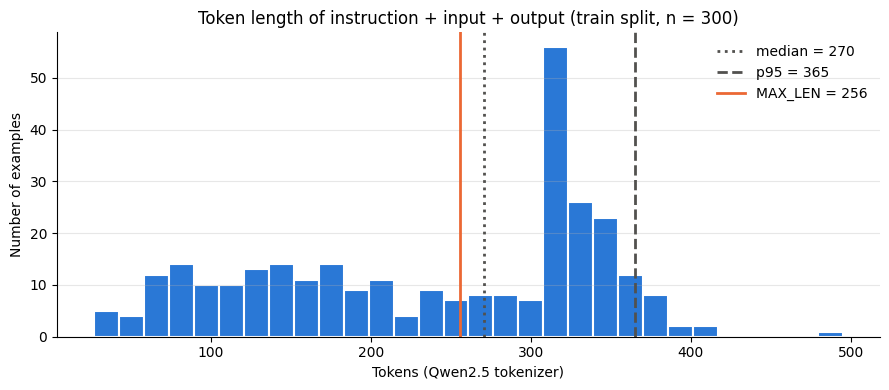

In [6]:
# ============================================================
#  Step 4: Load Dataset and Statistics
# ============================================================

# load the dataset and convert to pandas DataFrame
DATASET_IDS = ["lavita/AlpaCare-MedInstruct-52k",   # public HF copy of AlpaCare-MedInstruct-52k
               "xz97/MedInstruct"]                  # the authors' original upload (fallback mirror)
raw = None
for ds_id in DATASET_IDS:
    try:
        raw = load_dataset(ds_id, split="train")
        print(f"Loaded {ds_id}: {len(raw):,} rows | columns = {raw.column_names}")
        break
    except Exception as e:
        print(f"[warn] could not load {ds_id}: {type(e).__name__}: {str(e)[:150]}")
if raw is None:
    raise RuntimeError("AlpaCare-MedInstruct-52k could not be downloaded - check the runtime's internet access.")

df = raw.to_pandas()[["instruction", "input", "output"]].fillna("").astype(str)
for col in ["instruction", "input", "output"]:
    df[col] = df[col].str.strip()

# The dataset stores the literal token "<noinput>" when there is no extra context.
is_noinput = df["input"].str.fullmatch(r"(?i)<\s*no\s*input\s*>")
print(f"'<noinput>' placeholders blanked: {int(is_noinput.sum()):,} of {len(df):,} rows ({is_noinput.mean():.1%})")
df.loc[is_noinput, "input"] = ""
n_before = len(df)   # hygiene: every example needs an instruction and a non-empty reference to supervise
df = df[(df["instruction"] != "") & (df["output"] != "")].reset_index(drop=True)
print(f"Dropped {n_before - len(df)} rows with an empty instruction/output -> {len(df):,} usable rows")

# Shuffle once, then slice off the splits by index.
df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)      # ONE seeded shuffle of the pool
train_df = df.iloc[:N_TRAIN].reset_index(drop=True)                      # rows [0, 300)
val_df   = df.iloc[N_TRAIN:N_TRAIN + N_VAL].reset_index(drop=True)       # rows [300, 330)
test_df  = df.iloc[N_TRAIN + N_VAL:N_TRAIN + N_VAL + N_TEST].reset_index(drop=True)   # rows [330, 360)
assert (len(train_df), len(val_df), len(test_df)) == (N_TRAIN, N_VAL, N_TEST)
print(f"Split sizes -> train {len(train_df)} | val {len(val_df)} | test {len(test_df)}  "
      f"(disjoint index ranges after one shuffle, seed={SEED})")

# ---- Basic statistics on the training split ----
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

frac_with_input = (train_df["input"] != "").mean()

def combined_len(r):
    text = r["instruction"] + " " + r["input"] + " " + r["output"]
    return len(tokenizer(text, add_special_tokens=False)["input_ids"])

lens = train_df.apply(combined_len, axis=1)
len_stats = {"mean": lens.mean(), "median": lens.median(), "p95": lens.quantile(0.95), "max": lens.max()}

print("\nFields: instruction = the task/question | input = optional extra context | output = reference answer")
print(f"Rows with a non-empty `input` (train): {frac_with_input:.1%} "
      f"({int((train_df['input'] != '').sum())}/{len(train_df)})")

field_tok = pd.DataFrame({c: train_df[c].map(lambda s: len(tokenizer(s, add_special_tokens=False)["input_ids"]))
                          for c in ["instruction", "input", "output"]})
print("\nPer-field token lengths on the train split:")
print(field_tok.describe(percentiles=[0.5, 0.95]).T[["mean", "50%", "95%", "max"]].round(1).to_string())

print("\nCombined instruction + input + output token length (train):")
for k, v in len_stats.items():
    print(f"  {k:>6}: {v:7.1f}")
over = int((lens > MAX_LEN).sum())
print(f"  rows longer than MAX_LEN={MAX_LEN}: {over}/{len(lens)} ({over / len(lens):.1%})  "
      f"(the chat template adds a fixed overhead on top - measured in Step 5)")
print(f"\n📌 [S4] non-empty input = {frac_with_input:.1%} | mean {len_stats['mean']:.1f} | median {len_stats['median']:.0f} | "
      f"p95 {len_stats['p95']:.0f} | max {len_stats['max']:.0f} | >{MAX_LEN}: {over / len(lens):.1%} | "
      f"<noinput> rows in full set: {is_noinput.mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(lens, bins=30, color="#2a78d6", edgecolor="white", linewidth=1.5)
for x, lab, ls, col in [(len_stats["median"], "median", ":", "#52514e"),
                        (len_stats["p95"], "p95", "--", "#52514e"),
                        (MAX_LEN, "MAX_LEN", "-", "#eb6834")]:
    ax.axvline(x, color=col, linestyle=ls, linewidth=2, label=f"{lab} = {x:.0f}")
ax.set_title("Token length of instruction + input + output (train split, n = 300)")
ax.set_xlabel("Tokens (Qwen2.5 tokenizer)")
ax.set_ylabel("Number of examples")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### ✍️ Step 4 Reflection  <font color="red">[4 marks]</font>

**[Your Answer]** must cover:
- The three fields (`instruction`, `input`, `output`), what each holds, and roughly what fraction of rows use a non-empty `input`. **<font color="red">1 marks</font>**
- The token-length statistics you printed (mean / median / p95 / max) and the `MAX_LEN` you will adopt because of them — justify the choice against the p95. **<font color="red">2 marks</font>**
- That `output` is a *machine-generated* reference (text-davinci-003), and what that implies for treating it as ground truth when scoring models later. **<font color="red">1 marks</font>**

*Cite the actual numbers your run produced.*

### ✅ Your Answer — Step 4

**The three fields.** Every AlpaCare row is an Alpaca-style triple:
- `instruction` is the task or question. Train-split mean is 17.6 tokens, for example *"Identify which part of brain controls the sense of smell."*
- `input` is optional extra context: a patient vignette, a USMLE-style question with options, or a passage to summarise (mean 29.9 tokens).
- `output` is the reference answer (mean 190.1 tokens, median 203, p95 303, max 400).

When no context is needed, the dataset stores the literal string `<noinput>`. I blank that to `""`. It affected **16,757 of 52,002 rows (32.2%)**, and no rows had an empty instruction or output. In the 300-row training split, **69.0% of rows (207/300)** have a non-empty `input`.

**Token lengths → `MAX_LEN`.** The combined instruction + input + output length on the train split is:

| mean | median | p95 | max |
|---|---|---|---|
| **237.8** | **270.5** | **365** | **495** |

**51.0% of rows (153/300)** already exceed 256 tokens. The chat template adds another **26 tokens** (system message, role tags, EOS). After templating, the median is **296** and the p95 is **393**, so **170/300 examples (56.7%)** are truncated at 256.

I keep **`MAX_LEN = 256`**, and the numbers show this is a **compute budget, not a coverage choice**. Covering the p95 would need `MAX_LEN ≈ 400`, but 256 already sits *below the median*. I keep it for three reasons:
- **Memory.** Full IFT in fp32 peaked at **9.93 GB** on the 15 GB T4 *at* 256. The 151,936-way logits cost B·L·V·4 bytes, about 0.62 GB per fp32 copy at L = 256, and they grow linearly with L, as do activations and time. Going to about 400 would add roughly 55% to those terms and to every epoch's time.
- **Truncation only clips tails.** The prompt and the start of every answer are always kept, and EOS is reserved inside the budget. On average 139.7 answer tokens per example are still supervised; the minimum is 4, for a one-line answer.
- **Generation is capped at 200 new tokens**, so the evaluation cannot use much longer answers anyway.

The cost is real. Step 11 shows **14/30** test answers hitting the 200-token cap, and a longer `MAX_LEN` together with a higher `max_new_tokens` is the first thing I would change given more memory or time.

**Machine-generated references.** The `output` texts were written by OpenAI's **text-davinci-003** through a self-instruct pipeline seeded with clinician-written tasks. They were not written or checked answer-by-answer by clinicians. Three consequences:
- They can contain factual errors, outdated guidance or missing caveats. A model that reproduces them is not thereby clinically correct.
- They share davinci-003's style: long, structured, report-like (e.g. *"Title: … Introduction: … Cause: …"* in test #3). ROUGE-L and BERTScore therefore partly reward imitating that style.
- An open medical question has many valid answers, and the reference is only one sample.

I treat the outputs as **silver labels**. They are a common yardstick for *comparing* methods, not ground truth for medical accuracy.

## <font color="blue"><b>Step 5: Dataset, Collate, and DataLoaders</b></font>  <font color="red">**[14 marks]**</font>

Build the input pipeline as a hand-written `torch.utils.data.Dataset` (like the DPO demo), with tokenisation deferred to a `collate` function:

- **`SFTDataset`** — holds `(prompt, answer)` text pairs. The prompt is rendered with the tokenizer's **chat template** (instruction → *user* turn, primed to answer).
- **`tokenize_example`** — tokenises the full `prompt + answer` **once** and uses the **offset mapping** to mark exactly where the answer begins, producing a `comp_mask` (1 = answer token, 0 = prompt token).
- **`collate`** — pads a batch to its longest sequence and returns `input_ids`, `attn`, and `comp_mask`.
- **Three DataLoaders** — `train_loader` (shuffled), `val_loader`, `test_loader`.

Finally, print the **first full training batch** to confirm the shapes and the answer/prompt masking.

**Marks:** code <font color="red">**[10 marks]**</font> — `SFTDataset` + chat-template prompt, offset-based `comp_mask`, correct padded `collate`, three loaders, and the batch print; reflection <font color="red">**[4 marks]**</font> — see below.

In [7]:
# ============================================================
#  Step 5: Dataset, Collate, and DataLoaders
# ============================================================

SYSTEM_MSG = "You are a helpful medical assistant. Answer accurately and safely."

def build_prompt(instruction, input_text):
    user_msg = instruction.strip()
    if input_text and input_text.strip():                 # optional context goes under the instruction
        user_msg += "\n\nInput:\n" + input_text.strip()
    msgs = [{"role": "system", "content": SYSTEM_MSG},
            {"role": "user",   "content": user_msg}]      # add_generation_prompt=True primes the assistant turn
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)


class SFTDataset(Dataset):
    """Holds (prompt_text, answer_text) pairs; tokenisation is deferred to collate()."""
    def __init__(self, frame):
        self.rows = [{"prompt": build_prompt(r["instruction"], r["input"]),
                      "answer": r["output"].strip()}
                     for _, r in frame.iterrows()]
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        return self.rows[i]


# Tokens that close the user turn and open the assistant turn ("<|im_end|>\n<|im_start|>assistant\n").
_probe = build_prompt("X", "")
GEN_SUFFIX_LEN = len(tokenizer(_probe[_probe.rindex("X") + 1:], add_special_tokens=False)["input_ids"])
MIN_ANSWER_TOKENS = 16   # an over-long prompt can never crowd out the answer completely

def tokenize_example(prompt, answer):
    """
    Tokenise the full (prompt + answer) once and use the offset mapping to mark
    exactly where the answer begins. comp_mask = 1 on answer tokens, 0 on prompt.
    Tokenising once avoids token-merge drift at the boundary.
    """
    enc = tokenizer(prompt + answer, add_special_tokens=False, return_offsets_mapping=True)
    ids = list(enc["input_ids"])
    ans_start = len(prompt)                                   # first character of the answer
    mask = [1 if end > ans_start else 0 for (_, end) in enc["offset_mapping"]]   # token covers answer text

    budget = MAX_LEN - 1                                      # reserve the final slot for EOS
    n_prompt = mask.index(1) if 1 in mask else len(mask)
    if n_prompt > budget - MIN_ANSWER_TOKENS:                 # rare: trim the prompt's middle, keep the
        keep_head = max(budget - MIN_ANSWER_TOKENS - GEN_SUFFIX_LEN, 0)   # header + the "assistant\n" cue
        ids  = ids[:keep_head]  + ids[n_prompt - GEN_SUFFIX_LEN:]
        mask = mask[:keep_head] + mask[n_prompt - GEN_SUFFIX_LEN:]
    ids, mask = ids[:budget], mask[:budget]                   # long answers lose their tail, never their start
    ids.append(tokenizer.eos_token_id)                        # EOS (<|im_end|>) always fits inside MAX_LEN ...
    mask.append(1)                                            # ... and is supervised, so the model learns to stop
    return ids, mask


def collate(batch):
    """Pad a batch to its longest sequence. Returns input_ids, attn, comp_mask."""
    pairs = [tokenize_example(ex["prompt"], ex["answer"]) for ex in batch]
    longest = max(len(ids) for ids, _ in pairs)
    input_ids = torch.full((len(pairs), longest), tokenizer.pad_token_id, dtype=torch.long)
    attn      = torch.zeros((len(pairs), longest), dtype=torch.long)
    comp_mask = torch.zeros((len(pairs), longest), dtype=torch.long)
    for i, (ids, m) in enumerate(pairs):                      # right padding: real tokens first
        n = len(ids)
        input_ids[i, :n] = torch.tensor(ids, dtype=torch.long)
        attn[i, :n]      = 1                                  # pads stay 0 -> never attended to
        comp_mask[i, :n] = torch.tensor(m, dtype=torch.long)  # pads stay 0 -> never supervised
    return input_ids, attn, comp_mask


# ---- Three DataLoaders ----
train_ds, val_ds, test_ds = SFTDataset(train_df), SFTDataset(val_df), SFTDataset(test_df)
loader_gen = torch.Generator().manual_seed(SEED)              # train_model() re-seeds it -> same batch order every run
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate, generator=loader_gen)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)

print(f"Train batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")
print(f"Test batches  : {len(test_loader)}")

# ---- Print the first FULL batch of the train loader ----
input_ids, attn, comp_mask = next(iter(train_loader))
print(f"\ninput_ids {tuple(input_ids.shape)} {input_ids.dtype} | attn {tuple(attn.shape)} | comp_mask {tuple(comp_mask.shape)}")
print(f"pad id = {tokenizer.pad_token_id} ({tokenizer.pad_token!r}) | eos id = {tokenizer.eos_token_id} ({tokenizer.eos_token!r})")
torch.set_printoptions(threshold=1_000_000, linewidth=170)
print("\ninput_ids =\n", input_ids)
print("\nattn =\n", attn)
print("\ncomp_mask =\n", comp_mask)
torch.set_printoptions(profile="default")

real    = attn.sum(1)
sup     = comp_mask.sum(1)
prompt_ = real - sup
pad     = input_ids.shape[1] - real
print("\nrow | real tokens | prompt (masked, 0) | answer+EOS (supervised, 1) | padding (masked, 0)")
for i in range(input_ids.shape[0]):
    print(f" {i}  | {int(real[i]):11d} | {int(prompt_[i]):18d} | {int(sup[i]):26d} | {int(pad[i]):19d}")
tot = input_ids.numel()
print(f"batch | supervised = {int(sup.sum())} ({sup.sum() / tot:.1%}) | masked prompt = {int(prompt_.sum())} "
      f"({prompt_.sum() / tot:.1%}) | masked padding = {int(pad.sum())} ({pad.sum() / tot:.1%}) | total = {tot}")
assert all(input_ids[i, real[i] - 1].item() == tokenizer.eos_token_id for i in range(len(real))), "EOS missing"
assert (comp_mask * (1 - attn)).sum() == 0, "a padding position is supervised"

# Decode row 0 split by the mask, to eyeball the boundary.
row_ids, row_m = input_ids[0, :real[0]].tolist(), comp_mask[0, :real[0]].tolist()
print("\n--- row 0, PROMPT part (comp_mask = 0) ---")
print(tokenizer.decode([t for t, m in zip(row_ids, row_m) if m == 0]))
print("--- row 0, ANSWER part (comp_mask = 1) ---")
print(tokenizer.decode([t for t, m in zip(row_ids, row_m) if m == 1])[:600])

# Whole-train-split check of the masking/truncation rules.
full_lens, sup_counts, prompt_lens = [], [], []
for ex in train_ds.rows:
    ids_, m_ = tokenize_example(ex["prompt"], ex["answer"])
    full_lens.append(len(tokenizer(ex["prompt"] + ex["answer"], add_special_tokens=False)["input_ids"]) + 1)
    sup_counts.append(sum(m_))
    prompt_lens.append(len(m_) - sum(m_))
full_lens = np.array(full_lens)
overhead = len(tokenizer(build_prompt("", ""), add_special_tokens=False)["input_ids"]) + 1
print(f"\nChat-template overhead (system + role tags + EOS): {overhead} tokens per example")
print(f"Templated prompt+answer+EOS length (train): mean {full_lens.mean():.1f} | median {np.median(full_lens):.0f} | "
      f"p95 {np.percentile(full_lens, 95):.0f} | max {full_lens.max()}")
print(f"Examples truncated by MAX_LEN={MAX_LEN}: {(full_lens > MAX_LEN).sum()}/{len(full_lens)} "
      f"({(full_lens > MAX_LEN).mean():.1%}) | min supervised tokens/example = {min(sup_counts)} | "
      f"mean prompt tokens = {np.mean(prompt_lens):.1f} | mean supervised tokens = {np.mean(sup_counts):.1f}")
print(f"\n📌 [S5] batch {tuple(input_ids.shape)} | supervised {int(sup.sum())} | masked prompt {int(prompt_.sum())} | "
      f"padding {int(pad.sum())} | template overhead {overhead} | truncated {(full_lens > MAX_LEN).mean():.1%}")

Train batches : 75
Val batches   : 8
Test batches  : 8

input_ids (4, 256) torch.int64 | attn (4, 256) | comp_mask (4, 256)
pad id = 151643 ('<|endoftext|>') | eos id = 151645 ('<|im_end|>')

input_ids =
 tensor([[151644,   8948,    198,   2610,    525,    264,  10950,   6457,  17847,     13,  21806,  29257,    323,  21000,     13, 151645,    198, 151644,    872,    198,
          16141,    279,   2701,   3019,     12,     18,   1707,   2274,  25045,   3405,  18310,   8720,  22982,    382,   2505,    510,     32,    220,     17,     18,
           4666,   6284,   5220,    448,    902,   5089,   6457,   3840,   4041,    311,    279,   5163,   1576,    315,  74468,   1290,   4722,  55956,   6646,    369,
           1378,   3951,     13,    576,   6646,   5990,  12033,   2337,    296,   4280,    323,  39658,    369,   3807,   4115,    311,   2849,     13,  10698,  68429,
           2477,   3667,  70816,   7147,  66495,  10975,   3410,   6646,  15957,     13,   2932,    702,   4622,  77627

### ✍️ Step 5 Reflection  <font color="red">**[4 marks]**</font>

**[Your Answer]** must cover:
- Why the prompt uses the tokenizer's **chat template** for an `-Instruct` model (special tokens must match what the model saw in pre-training). <font color="red">**[1]**</font>
- What `comp_mask` encodes and why we compute the loss on the **answer tokens only** (completion-only). <font color="red">**[1]**</font>
- Why tokenising `prompt + answer` **once with offsets** is more correct than tokenising them separately and concatenating (avoids token-merge drift at the boundary). <font color="red">**[1]**</font>
- From the printed batch: the supervised-vs-masked token counts, and why padding fills `input_ids` with the pad token but `comp_mask` with 0. <font color="red">**[1]**</font>

*Cite the actual numbers your run produced.*

### ✅ Your Answer — Step 5

**Why the chat template.** Qwen2.5-0.5B-*Instruct* was post-trained on ChatML. Every turn is `<|im_start|>role\n … <|im_end|>\n`, and `<|im_start|>assistant\n` cues the reply. These are dedicated special tokens whose embeddings were learned in exactly this arrangement. `apply_chat_template(..., add_generation_prompt=True)` reproduces that layout exactly: system turn, then user turn, then an open assistant turn (see the printed row 0). This gives three benefits:
- Fine-tuning only has to change *what* the model says, not teach it a new format.
- `generate_answers` builds prompts with the same `build_prompt`, so training and test prompts are identical.
- The supervised answer ends with `<|im_end|>` (id 151645), the token `generate()` stops on.

A home-made `### Instruction:` format would be out of distribution for an Instruct model and would spend the 300 examples on learning formatting.

**What `comp_mask` encodes.** `comp_mask[i, t] = 1` exactly when token *t* belongs to the reference answer or is the final `<|im_end|>`. It is 0 for the system message, the user turn, the role tags and all padding. The loss averages next-token NLL only over positions whose **target** has `comp_mask = 1` (completion-only).

At inference the prompt is given, never generated, so there is nothing useful to learn from predicting it. Across the train split, prompts average **73.9 tokens**, and the system message (identical in all 300 rows) makes many of them trivially predictable. Training on them would dilute the gradient spread over the **139.7** answer tokens per example, make the loss look artificially low, and could teach the model to write user turns. Supervising EOS teaches the model *when to stop*.

**Why tokenise once with offsets.** BPE merges depend on neighbouring characters, so `tok(prompt) + tok(answer)` is not guaranteed to equal `tok(prompt + answer)`. At the seam, characters can merge into a different token ("token-merge drift"). The training ids would then differ from what the model sees at inference, and the mask boundary could be off by one.

I tokenise the full string once with `return_offsets_mapping`. Each token then carries its character span, and a token is marked as answer if its span ends after `len(prompt)`. The boundary is exact even if a token straddles it. In the printed decode of row 0, the masked part ends exactly at `<|im_start|>assistant\n` and the supervised part starts at *"The most likely diagnosis … C) Endometriosis."* and ends with `<|im_end|>`.

**The printed batch.** Shape **(4, 256)**, 1,024 positions:

| Tokens | Count | Share |
|---|---|---|
| Supervised (answer + EOS) | **507** | 49.5% |
| Masked prompt | **433** | 42.3% |
| Masked padding | **84** | 8.2% |

Three rows fill all 256 slots because they were truncated. Row 0 is a long USMLE vignette: 187 prompt tokens and 69 answer tokens. Row 2 has 172 real tokens followed by 84 pads.

Padding fills `input_ids` with the pad id `<|endoftext|>` (**151643**) because the tensor must be rectangular and every slot needs a valid vocabulary id for the embedding lookup. That id is distinct from EOS `<|im_end|>` (**151645**), and `attn = 0` there, so real tokens never attend to it.

`comp_mask` is 0 on padding because padding is not part of any answer. Supervising it would train the model to emit filler after EOS, and the loss would depend on how much padding a batch happens to contain. The code asserts that no padded position is supervised.

## <font color="blue"><b>Step 6: Model Loading and Full Instruction Fine-Tuning (IFT)</b></font>  <font color="red">**[20 marks]**</font>

This is the core of the notebook. First define the training machinery that all three methods reuse, then run full fine-tuning:

- **`batch_loss`** — the causal-LM next-token loss, but computed over **answer tokens only** (using `comp_mask`), so the model is never scored on re-typing the prompt.
- **`eval_loss`** — averages `batch_loss` over a whole loader (no gradients), used for validation.
- **`train_model`** — the shared manual training loop: gradient accumulation, warmup → cosine schedule, gradient clipping, per-epoch train/val history, and early stopping on validation loss. Returns the best model plus its history, training time, and peak memory.

Then load Qwen2.5-0.5B in **fp32** (pure fp16 full fine-tuning overflows on this model), confirm ~100% of parameters are trainable, run **full IFT** with the small learning rate `LR_FULL`, and print the per-epoch train/val losses.

**Marks:** code <font color="red">**[14 marks]**</font> — correct answer-only `batch_loss`, the `train_model` loop (accumulation, schedule, clipping, early stopping, history), fp32 model load, and the IFT run with per-epoch report; reflection <font color="red">**[6 marks]**</font> — see below.

In [8]:
# ============================================================
#  Step 6: Load Model and Full Instruction Fine-Tuning (IFT)
# ============================================================

# ---- Loss over ANSWER tokens only (comp_mask == 1) ----
def batch_loss(model, input_ids, attn, comp_mask):
    """Mean next-token NLL over answer tokens for ONE batch."""
    input_ids, attn, comp_mask = input_ids.to(DEVICE), attn.to(DEVICE), comp_mask.to(DEVICE)
    logits = model(input_ids=input_ids, attention_mask=attn, use_cache=False).logits
    # causal shift: the logits at position t predict the token at position t+1
    logp = F.log_softmax(logits[:, :-1, :].float(), dim=-1)            # fp32 log-probs (stable for fp16 compute too)
    tok  = logp.gather(-1, input_ids[:, 1:].unsqueeze(-1)).squeeze(-1)  # log p(true next token), shape [B, T-1]
    mask = comp_mask[:, 1:].to(tok.dtype)                               # 1 where the TARGET is an answer/EOS token
    return -(tok * mask).sum() / mask.sum().clamp(min=1.0)


@torch.no_grad()
def eval_loss(model, loader):
    """Average batch_loss over an entire loader (no gradients)."""
    was_training = model.training
    model.eval()                                   # no dropout during evaluation
    tot, n = 0.0, 0
    for input_ids, attn, comp_mask in loader:
        tot += batch_loss(model, input_ids, attn, comp_mask).item()
        n += 1
    if was_training:
        model.train()
    return tot / max(n, 1)


# ---- Shared training loop (reused for IFT, LoRA, QLoRA) ----
def train_model(model, lr, tag):
    """
    Manual training loop: gradient accumulation, warmup->cosine schedule,
    gradient clipping, and early stopping on validation loss.
    Returns (best_model, hist, train_time_s, peak_mem_gb).
    hist keys: 'train_loss' & 'val_loss' (per epoch), 'step_loss' (per step).
    """
    seed_everything()
    free_memory()

    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    trainable_keys = {n for n, p in model.named_parameters() if p.requires_grad}   # only these change
    total_steps = math.ceil(len(train_loader) / GRAD_ACCUM) * EPOCHS
    scheduler = get_cosine_schedule_with_warmup(
        optimizer, int(WARMUP_RATIO * total_steps), total_steps)

    hist = {"train_loss": [], "val_loss": [], "step_loss": []}
    best_val, best_epoch, best_state, no_improve, PATIENCE = float("inf"), 0, None, 0, 2

    t0 = time.time()

    params = [p for p in model.parameters() if p.requires_grad]
    if torch.cuda.is_available():
        print(f"[{tag}] GPU memory resident at start = {torch.cuda.memory_allocated() / 1e9:.2f} GB")
    print(f"[{tag}] lr={lr:g} | effective batch = {BATCH_SIZE}x{GRAD_ACCUM} = {BATCH_SIZE * GRAD_ACCUM} | "
          f"optimizer steps = {total_steps} (warmup {int(WARMUP_RATIO * total_steps)})")
    train_loader.generator.manual_seed(SEED)       # identical shuffling for every run -> fair comparison
    step = 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        ep_loss, n_batches, window = 0.0, 0, []
        for it, (input_ids, attn, comp_mask) in enumerate(train_loader, 1):
            loss = batch_loss(model, input_ids, attn, comp_mask)
            (loss / GRAD_ACCUM).backward()                         # gradient accumulation (scaled)
            ep_loss += loss.item(); n_batches += 1; window.append(loss.item())
            if it % GRAD_ACCUM == 0 or it == len(train_loader):    # one optimizer step per GRAD_ACCUM micro-batches
                torch.nn.utils.clip_grad_norm_(params, MAX_GRAD_NORM)   # gradient clipping (global L2 norm <= 1)
                optimizer.step()
                scheduler.step()                                    # linear warmup, then cosine decay
                optimizer.zero_grad(set_to_none=True)
                step += 1
                hist["step_loss"].append(sum(window) / len(window)); window = []
        train_loss = ep_loss / max(n_batches, 1)
        val_loss = eval_loss(model, val_loader)
        hist["train_loss"].append(train_loss)
        hist["val_loss"].append(val_loss)
        print(f"[{tag}] epoch {epoch}/{EPOCHS} | train {train_loss:.4f} | val {val_loss:.4f} | "
              f"lr {scheduler.get_last_lr()[0]:.2e} | step {step}/{total_steps} | {time.time() - t0:.0f}s")

        if val_loss < best_val:                                     # early-stopping bookkeeping
            best_val, best_epoch, no_improve = val_loss, epoch, 0
            # snapshot ONLY the trainable tensors, on CPU (4-bit quant-state buffers are never copied)
            best_state = {k: v.detach().to("cpu", copy=True)
                          for k, v in model.state_dict().items() if k in trainable_keys}
        else:
            no_improve += 1
            if no_improve >= PATIENCE:
                print(f"[{tag}] early stopping: no val improvement for {PATIENCE} epochs")
                break

    if best_state is not None:                                      # restore the best-validation weights
        res = model.load_state_dict(best_state, strict=False)       # strict=False: trainable params only
        assert not res.unexpected_keys, res.unexpected_keys
    model.eval()

    train_time, peak_mem = time.time() - t0, gpu_mem_gb()
    print(f"[{tag}] best epoch = {best_epoch} | time = {train_time:.1f}s | peak mem = {peak_mem:.2f} GB")
    return model, hist, train_time, peak_mem


# ---- Load model for Full IFT ----
# fp32 (not fp16): pure-fp16 full fine-tuning overflows on Qwen2.5 and gives a
# garbage loss in the hundreds. fp32 is fine for a 0.5B model on a T4.
seed_everything()
free_memory()

import transformers
from packaging import version
# transformers >= 4.56 renamed `torch_dtype` to `dtype`; pick whichever this runtime understands
DTYPE_KW = "dtype" if version.parse(transformers.__version__) >= version.parse("4.56.0") else "torch_dtype"

def park(model, tag):
    """After training, move a full-precision model to CPU RAM (so the next run's GPU peak is isolated) when
    at least 3 GB of RAM would remain; otherwise keep it on the GPU - its memory is then subtracted as 'resident'."""
    need = sum(p.numel() * p.element_size() for p in model.parameters())
    try:
        import psutil
        room = psutil.virtual_memory().available > need + 3e9
    except ImportError:
        room = False
    if DEVICE == "cuda" and room:
        model.to("cpu")
    free_memory()
    print(f"[{tag}] trained model kept on {'CPU RAM' if room or DEVICE != 'cuda' else 'GPU (not enough RAM to park)'}")

full_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, **{DTYPE_KW: torch.float32}).to(DEVICE)
full_model.config.use_cache = False                                  # no KV cache while training
full_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
tr_full, tot_full, pct_full = count_trainable(full_model)
print(f"Full IFT | dtype = {next(full_model.parameters()).dtype} | trainable = {tr_full:,} / {tot_full:,} "
      f"({pct_full:.2f}%) | gradient checkpointing = {full_model.is_gradient_checkpointing}")

full_model, full_hist, full_time, full_mem = train_model(full_model, LR_FULL, "full_ift")

park(full_model, "full_ift")      # isolate the next runs' GPU-memory readings
print(f"\n📌 [S6] trainable {tr_full:,} ({pct_full:.2f}%) | time {full_time:.1f}s | peak mem {full_mem:.2f} GB | "
      f"best val {min(full_hist['val_loss']):.4f} (epoch {int(np.argmin(full_hist['val_loss'])) + 1})")

# ---- Per-epoch loss history ----
print("\nEpoch |  Train Loss | Val Loss")
print("-" * 34)
for ep, (tl, vl) in enumerate(zip(full_hist["train_loss"], full_hist["val_loss"]), 1):
    print(f"  {ep:2d}  |   {tl:.4f}   | {vl:.4f}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Full IFT | dtype = torch.float32 | trainable = 494,032,768 / 494,032,768 (100.00%) | gradient checkpointing = True
[full_ift] GPU memory resident at start = 1.98 GB
[full_ift] lr=1e-05 | effective batch = 4x1 = 4 | optimizer steps = 225 (warmup 11)
[full_ift] epoch 1/3 | train 1.1744 | val 1.1174 | lr 7.95e-06 | step 75/225 | 110s
[full_ift] epoch 2/3 | train 0.5401 | val 1.1848 | lr 2.74e-06 | step 150/225 | 223s
[full_ift] epoch 3/3 | train 0.2487 | val 1.3623 | lr 0.00e+00 | step 225/225 | 335s
[full_ift] early stopping: no val improvement for 2 epochs
[full_ift] best epoch = 1 | time = 335.4s | peak mem = 9.93 GB
[full_ift] trained model kept on CPU RAM

📌 [S6] trainable 494,032,768 (100.00%) | time 335.4s | peak mem 9.93 GB | best val 1.1174 (epoch 1)

Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.1744   | 1.1174
   2  |   0.5401   | 1.1848
   3  |   0.2487   | 1.3623


### ✍️ Step 6 Reflection  <font color="red">**[6 marks]**</font>

**[Your Answer]** must cover:
- How `batch_loss` supervises **only** the answer tokens (the `comp_mask` shift + masked mean), and how completion-only loss differs from training on the whole sequence. <font color="red">**[2 marks]**</font>
- Where warmup, cosine decay, gradient clipping, and gradient accumulation appear in `train_model`, and your **effective batch size** (`BATCH_SIZE × GRAD_ACCUM`). <font color="red">**[2 marks]**</font>
- Why full IFT is loaded in **fp32** (pure fp16 full fine-tuning overflows on Qwen2.5) and why its learning rate `LR_FULL = 1e-5` is deliberately small. <font color="red">**[1 marks]**</font>
- The per-epoch train/val trend — is the model improving or starting to overfit? <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

### ✅ Your Answer — Step 6

**How `batch_loss` supervises only the answer.**
- **Shift.** A causal LM's logits at position *t* are a distribution over token *t+1*. `batch_loss` therefore aligns `logits[:, :-1]` with the targets `input_ids[:, 1:]`.
- **Per-token log-probability.** It applies `log_softmax` in fp32 and uses `gather` to read the log-probability of each true next token. The result `tok` has shape [B, T−1].
- **Shifted mask.** The mask is shifted the same way (`comp_mask[:, 1:]`), so position *t* counts exactly when its *target* is an answer or EOS token. The first answer token is predicted from the last prompt token (`assistant\n`), and no prompt or pad target ever contributes.
- **Masked mean.** The loss is `−Σ(tok·mask) / Σmask`, the mean NLL per supervised token across the batch. This is equivalent to HF's built-in loss with `labels = −100` on masked positions.

Whole-sequence training would also average in the prompt tokens: 433 of the 1,024 positions in the printed batch. Those are easy and largely repeated, so the loss would look lower, the gradient would be spent on copying the prompt, and the model would partly learn to produce system and user text.

**Where the optimisation pieces sit in `train_model`.**
- **Gradient accumulation:** each micro-batch loss is divided by `GRAD_ACCUM` before `.backward()`. The optimiser steps only when `it % GRAD_ACCUM == 0` or on the last batch.
- **Gradient clipping:** `clip_grad_norm_(params, 1.0)` runs right before every `optimizer.step()`, capping the global gradient L2 norm so one unusual batch cannot cause a huge update.
- **Warmup → cosine:** `get_cosine_schedule_with_warmup(opt, 11, 225)`, with `scheduler.step()` after each optimiser step. The LR ramps linearly from 0 to peak over **11 warmup steps** (5% of 225), while AdamW's moment estimates are still noisy. It then follows a half-cosine down to 0. The log shows the LR at 7.95e-06 after epoch 1, 2.74e-06 after epoch 2 and 0 at step 225.
- **Effective batch:** `BATCH_SIZE × GRAD_ACCUM = 4 × 1 = 4` sequences per update, which gives **75 updates per epoch and 225 in total**.
- **Also:** AdamW over trainable parameters only, per-epoch train/val history, and early stopping with patience 2. The best epoch's *trainable* tensors are snapshotted to CPU and restored with `load_state_dict(strict=False)`.

**Why fp32 and a small LR.** fp16 tops out around 65,504 and has an 11-bit significand. In *pure* fp16 full fine-tuning (no fp32 master weights, no loss scaling) two things break on Qwen2.5:
- Some activations and logits overflow to inf/NaN, which shows up as the "loss in the hundreds".
- Updates of size lr × grad ≈ 1e-5 fall below fp16's resolution relative to the weights, so many of them round to zero.

fp32 avoids both problems and is affordable at 0.5B: 1.98 GB of weights (the "resident at start" reading) + 1.98 GB of gradients + 3.95 GB of AdamW moments ≈ 7.9 GB of static memory. The measured peak was **9.93 GB** of the T4's 15 GB.

`LR_FULL = 1e-5` is small because all **494,032,768** weights move. The model is already instruction-tuned and there are only 300 examples, so a large LR would overwrite general knowledge (catastrophic forgetting) and memorise the training set even faster than it already does (see the trend below).

**Trend: clear overfitting after epoch 1.**

| | Epoch 1 | Epoch 2 | Epoch 3 |
|---|---|---|---|
| Train loss | **1.1744** | **0.5401** | **0.2487** |
| Validation loss | **1.1174** | **1.1848** | **1.3623** |

Training loss falls by 79% while validation loss *rises* by 0.245. With 494M free parameters and only 300 examples, one pass is enough to adapt, and further passes memorise the training answers. The val − train gap reaches **1.11**. Early stopping did its job: validation did not improve for two epochs, so the **epoch-1 weights (val 1.1174)** were restored, and those are the weights evaluated in Step 9. A single epoch, or a lower LR, would be the right budget for full IFT here.

## <font color="blue"><b>Step 7: LoRA Fine-Tuning — r = 8 and r = 16</b></font>  <font color="red">**[14 marks]**</font>

Now freeze the backbone and train only small low-rank adapter matrices. For a frozen weight `W`, LoRA learns `A` and `B` and adds `(α/r)·B·A` as a correction — so only a tiny fraction of the parameters are trained.

Run LoRA at **two ranks, r = 8 and r = 16**, holding the `alpha/rank` ratio fixed (`alpha = 2·r`) so you isolate the effect of *rank* alone. Reuse the same `train_model` loop, store each run in `lora_runs[rank]`, and report the trainable-parameter percentage and per-epoch losses for both.

*(The `torchao` uninstall here avoids a T4 incompatibility that can otherwise break the peft/quantised path in the next step.)*

**Marks:** code <font color="red">**[8 marks]**</font> — correct `LoraConfig` (rank, alpha, dropout, target modules), the two-rank sweep reusing `train_model`, and the trainable-% + per-epoch report for each rank; reflection <font color="red">**[6 marks]**</font> — see below.

In [9]:
LORA_RANKS = [8, 16]   # compare two LoRA ranks
# ============================================================
#  Step 7: LoRA Fine-Tuning (rank sweep: r = 8 and r = 16)
# ============================================================

def build_lora_model(rank):
    """Fresh fp32 backbone + LoRA adapters at the given rank."""
    seed_everything()
    free_memory()
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, **{DTYPE_KW: torch.float32}).to(DEVICE)
    base.config.use_cache = False
    base.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})  # same as IFT/QLoRA
    base.enable_input_require_grads()
    cfg = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=rank,
        lora_alpha=2 * rank,                 # alpha/r = 2 at every rank -> only the rank changes
        lora_dropout=LORA_DROPOUT,
        bias="none",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj",       # attention projections
                        "gate_proj", "up_proj", "down_proj"],         # MLP projections
    )
    seed_everything()                        # identical adapter init for LoRA and QLoRA at the same rank
    return get_peft_model(base, cfg)


# ---- Run LoRA at each rank ----
lora_runs = {}   # rank -> dict(model, hist, time, mem, pct)

for rank in LORA_RANKS:
    foreign_gb = torch.cuda.memory_allocated() / 1e9 if torch.cuda.is_available() else 0.0   # other models on GPU
    model = build_lora_model(rank)
    print(f"\n================  LoRA  r = {rank}  (alpha = {2 * rank})  ================")
    model.print_trainable_parameters()
    trainable, total = model.get_nb_trainable_parameters()
    pct = 100 * trainable / total

    model, hist, run_time, run_mem = train_model(model, LR_LORA, f"lora_r{rank}")
    run_mem -= foreign_gb                    # isolated peak: exclude memory held by any other resident model
    park(model, f"lora_r{rank}")             # isolate the next run's peak-memory reading
    lora_runs[rank] = dict(model=model, hist=hist, time=run_time, mem=run_mem, pct=pct,
                           trainable=trainable, total=total)
    print(f"📌 [S7 r={rank}] trainable {trainable:,} / {total:,} = {pct:.4f}% | time {run_time:.1f}s | "
          f"peak mem {run_mem:.2f} GB | best val {min(hist['val_loss']):.4f} "
          f"(epoch {int(np.argmin(hist['val_loss'])) + 1})")

    print("\nEpoch |  Train Loss | Val Loss")
    print("-" * 34)
    for ep, (tl, vl) in enumerate(zip(hist["train_loss"], hist["val_loss"]), 1):
        print(f"  {ep:2d}  |   {tl:.4f}   | {vl:.4f}")
    print()

    free_memory()   # clear before the next rank

d_val = min(lora_runs[16]["hist"]["val_loss"]) - min(lora_runs[8]["hist"]["val_loss"])
print(f"📌 [S7] best val r16 - r8 = {d_val:+.4f} | params x{lora_runs[16]['trainable'] / lora_runs[8]['trainable']:.1f} | "
      f"vs full IFT: r8 trains {tr_full / lora_runs[8]['trainable']:.0f}x fewer, r16 {tr_full / lora_runs[16]['trainable']:.0f}x fewer")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


================  LoRA  r = 8  (alpha = 16)  ================
trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826
[lora_r8] GPU memory resident at start = 2.01 GB
[lora_r8] lr=0.0002 | effective batch = 4x1 = 4 | optimizer steps = 225 (warmup 11)
[lora_r8] epoch 1/3 | train 1.1527 | val 1.0754 | lr 1.59e-04 | step 75/225 | 91s
[lora_r8] epoch 2/3 | train 0.9036 | val 1.0849 | lr 5.47e-05 | step 150/225 | 183s
[lora_r8] epoch 3/3 | train 0.7277 | val 1.1251 | lr 0.00e+00 | step 225/225 | 275s
[lora_r8] early stopping: no val improvement for 2 epochs
[lora_r8] best epoch = 1 | time = 274.6s | peak mem = 4.01 GB
[lora_r8] trained model kept on GPU (not enough RAM to park)
📌 [S7 r=8] trainable 4,399,104 / 498,431,872 = 0.8826% | time 274.6s | peak mem 3.99 GB | best val 1.0754 (epoch 1)

Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.1527   | 1.0754
   2  |   0.9036   | 1.0849
   3  |   0.7277   | 1.1251



Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


================  LoRA  r = 16  (alpha = 32)  ================
trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
[lora_r16] GPU memory resident at start = 4.02 GB
[lora_r16] lr=0.0002 | effective batch = 4x1 = 4 | optimizer steps = 225 (warmup 11)
[lora_r16] epoch 1/3 | train 1.1525 | val 1.0733 | lr 1.59e-04 | step 75/225 | 92s
[lora_r16] epoch 2/3 | train 0.7879 | val 1.1099 | lr 5.47e-05 | step 150/225 | 183s
[lora_r16] epoch 3/3 | train 0.5395 | val 1.2133 | lr 0.00e+00 | step 225/225 | 275s
[lora_r16] early stopping: no val improvement for 2 epochs
[lora_r16] best epoch = 1 | time = 274.8s | peak mem = 6.06 GB
[lora_r16] trained model kept on GPU (not enough RAM to park)
📌 [S7 r=16] trainable 8,798,208 / 502,830,976 = 1.7497% | time 274.8s | peak mem 4.05 GB | best val 1.0733 (epoch 1)

Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.1525   | 1.0733
   2  |   0.7879   | 1.1099
   3  |   0.5395   | 1.2133

📌 [S7] best val r1

### ✍️ Step 7 Reflection  <font color="red">**[6 marks]**</font>

**[Your Answer]** must cover:
- The role of the **rank `r`** and **alpha `α`** (the `α/r` scaling), and why `B` is zero-initialised (the adapter starts as identity, so training is stable from step 0). <font color="red">**[2 marks]**</font>
- The **% trainable parameters** at r = 8 vs r = 16 (from `print_trainable_parameters`), and how both compare to full IFT's ~100%. <font color="red">**[2 marks]**</font>
- The effect of doubling the rank on validation loss — did r = 16 actually help, or just cost more parameters for the same quality? Cite both runs. <font color="red">**[1 marks]**</font>
- Why LoRA can safely use a much larger learning rate (`LR_LORA = 2e-4`) than full IFT. <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

### ✅ Your Answer — Step 7

**Rank, alpha and zero-initialised B.** LoRA keeps `W ∈ ℝ^{d×k}` frozen and learns a correction `ΔW = (α/r)·B·A`, with `A ∈ ℝ^{r×k}` and `B ∈ ℝ^{d×r}`.
- **Rank r** is the width of that bottleneck. It caps the rank of ΔW, i.e. how many independent directions the adaptation can use, and sets the cost: `r·(d+k)` parameters per adapted matrix.
- **α** is a scale. The multiplier α/r keeps the size of the update comparable when r changes. I set α = 2r (16 for r = 8, 32 for r = 16), so both runs use α/r = 2 and **only capacity differs, not step size**.
- **B is zero-initialised** while A is random (Kaiming). So `B·A = 0` and the adapted layer is exactly the pre-trained layer at step 0: the adapter starts as an identity correction. The starting loss is the base model's, and no random perturbation hits a good model, so training is stable from step 0. Learning still starts immediately, because `∂L/∂B = (∂L/∂h)(A x)ᵀ ≠ 0` when A ≠ 0. If A were zero as well, the gradient would vanish.

**% trainable vs full IFT.** These are the `print_trainable_parameters()` outputs:

| | Trainable | Total | % trainable | Vs full IFT |
|---|---|---|---|---|
| LoRA r = 8 | **4,399,104** | 498,431,872 | **0.8826%** | **112× fewer** |
| LoRA r = 16 | **8,798,208** | 502,830,976 | **1.7497%** | **56× fewer** |
| Full IFT | 494,032,768 | 494,032,768 | 100% | — |

Doubling r exactly doubles the adapter, because there are 22,912·r adapter parameters per layer across 7 projections in each of 24 layers. Fewer trainable parameters also means far less optimiser state. Peak memory fell from 9.93 GB (full IFT) to **3.99 GB** (r = 8) and **4.05 GB** (r = 16), most of which is now the frozen fp32 backbone and the activations.

**Effect of doubling the rank: r = 16 did not help.**

| | Best val loss | Test ROUGE-L | Test BERTScore-F1 | Train loss, epoch 3 | Val loss, epoch 3 |
|---|---|---|---|---|---|
| r = 8 | 1.0754 (epoch 1) | **0.3485** | 0.9011 | 0.7277 | 1.1251 |
| r = 16 | 1.0733 (epoch 1) | 0.3201 | 0.8980 | 0.5395 | 1.2133 |

The best-validation difference is only **−0.0020**, which is noise for 30 validation prompts. On the test set r = 16 is *worse* on both metrics. The extra capacity was spent memorising: r = 16's training loss fell further, and its validation loss rose faster. With 300 examples, rank 8 already captures the shift in answer style, so r = 16 cost twice the adapter parameters (+0.06 GB, +0.2 s) for no gain.

**Why LoRA tolerates `LR_LORA = 2e-4` (20× `LR_FULL`).**
- **The backbone is frozen**, so pre-trained knowledge cannot be overwritten. Only a small low-rank correction is learned.
- **ΔW starts at exactly 0** (B = 0) and grows gradually, and its size is tempered by α/r. Large steps on A and B still produce a small, controlled change in W early on.
- **The low-rank parameterisation is a strong regulariser.** At 20× the LR, LoRA r = 8 still overfit far less than full IFT: its epoch-3 val − train gap is 0.40 against full IFT's 1.11.
- **At 1e-5 the adapters would barely leave zero** in 225 steps. A larger LR is *needed* for them to learn anything.

## <font color="blue"><b>Step 8: QLoRA Fine-Tuning — r = 8 and r = 16</b></font>  <font color="red">**[14 marks]**</font>

LoRA froze the backbone but still kept it in full precision, which dominates GPU memory. **QLoRA** stores that frozen backbone in **4-bit NF4** instead, then trains the *same* LoRA adapters on top — the only thing that changes from Step 7 is the backbone's precision, making this a clean controlled comparison.

Set the 4-bit recipe with `BitsAndBytesConfig` (NF4, double quantisation, fp16 compute for the T4), call `prepare_model_for_kbit_training` before attaching the adapters, and run the **same two-rank sweep (r = 8 and r = 16)**. Store each run in `qlora_runs[rank]` and report the trainable-parameter percentage and per-epoch losses.

**Marks:** code <font color="red">**[8 marks]**</font> — correct `BitsAndBytesConfig`, `prepare_model_for_kbit_training`, the same `LoraConfig` as Step 7, the two-rank sweep reusing `train_model`, and the trainable-% + per-epoch report; reflection <font color="red">**[6 marks]**</font> — see below.

In [10]:
# ============================================================
#  Step 8: QLoRA Fine-Tuning (4-bit NF4 backbone; rank sweep: r = 8 and r = 16)
# ============================================================

def build_qlora_model(rank):
    """Fresh 4-bit NF4 backbone + LoRA adapters at the given rank."""
    seed_everything()
    free_memory()

    bnb_cfg = BitsAndBytesConfig(
        load_in_4bit=True,                       # frozen linear weights stored in 4 bits
        bnb_4bit_quant_type="nf4",               # NormalFloat-4 levels, matched to ~Gaussian weights
        bnb_4bit_use_double_quant=True,          # quantise the per-block scales too
        bnb_4bit_compute_dtype=torch.float16,    # de-quantise to fp16 for the matmuls (T4: no bf16)
    )
    base = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config=bnb_cfg,
        device_map={"": 0} if torch.cuda.is_available() else {"": "cpu"},
        **{DTYPE_KW: torch.float16},
    )
    base.config.use_cache = False
    # BEFORE attaching LoRA: freeze base, up-cast norms/embeddings to fp32, enable gradient checkpointing
    base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=True,
                                           gradient_checkpointing_kwargs={"use_reentrant": False})
    cfg = LoraConfig(                            # exactly the Step-7 adapter recipe
        task_type=TaskType.CAUSAL_LM,
        r=rank,
        lora_alpha=2 * rank,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                        "gate_proj", "up_proj", "down_proj"],
    )
    seed_everything()                            # same adapter initialisation as LoRA at this rank
    return get_peft_model(base, cfg)


# ---- Run QLoRA at each rank ----
qlora_runs = {}   # rank -> dict(model, hist, time, mem, pct)

for rank in LORA_RANKS:

    foreign_gb = torch.cuda.memory_allocated() / 1e9 if torch.cuda.is_available() else 0.0   # e.g. QLoRA r=8 kept on GPU
    model = build_qlora_model(rank)
    print(f"\n================  QLoRA  r = {rank}  (alpha = {2 * rank}, 4-bit NF4 backbone)  ================")
    model.print_trainable_parameters()           # peft counts each packed 4-bit element as 2 weights
    trainable, total = model.get_nb_trainable_parameters()
    pct = 100 * trainable / total
    raw_tr, raw_tot, raw_pct = count_trainable(model)
    print(f"count_trainable(): {raw_tr:,} / {raw_tot:,} = {raw_pct:.4f}%  <- numel() of packed uint8 storage "
          f"(2 x 4-bit weights per element) shrinks the denominator; the trainable count itself is unchanged")
    lc = lora_runs[rank]["model"].peft_config["default"]
    qc = model.peft_config["default"]
    same_cfg = all(getattr(lc, k) == getattr(qc, k) for k in ["r", "lora_alpha", "lora_dropout", "bias", "target_modules"])
    print(f"Same LoraConfig as LoRA r={rank}: {same_cfg} | same trainable count: {trainable == lora_runs[rank]['trainable']}")
    assert same_cfg and trainable == lora_runs[rank]["trainable"]

    model, hist, run_time, run_mem = train_model(model, LR_LORA, f"qlora_r{rank}")
    run_mem -= foreign_gb                        # isolated peak (4-bit models stay on the GPU for evaluation)
    qlora_runs[rank] = dict(model=model, hist=hist, time=run_time, mem=run_mem, pct=pct,
                            trainable=trainable, total=total, raw_pct=raw_pct, resident_other_gb=foreign_gb)
    print(f"📌 [S8 r={rank}] trainable {trainable:,} = {pct:.4f}% (count_trainable: {raw_pct:.4f}%) | "
          f"time {run_time:.1f}s | peak mem {run_mem:.2f} GB (excl. {foreign_gb:.2f} GB other resident) | "
          f"best val {min(hist['val_loss']):.4f} vs LoRA {min(lora_runs[rank]['hist']['val_loss']):.4f} | "
          f"mem vs LoRA {run_mem - lora_runs[rank]['mem']:+.2f} GB "
          f"({run_mem / lora_runs[rank]['mem'] - 1 if lora_runs[rank]['mem'] > 0 else float('nan'):+.0%})")

    print("\nEpoch |  Train Loss | Val Loss")
    print("-" * 34)
    for ep, (tl, vl) in enumerate(zip(hist["train_loss"], hist["val_loss"]), 1):
        print(f"  {ep:2d}  |   {tl:.4f}   | {vl:.4f}")
    print()

    free_memory()   # clear before the next rank

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


================  QLoRA  r = 8  (alpha = 16, 4-bit NF4 backbone)  ================
trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826
count_trainable(): 4,399,104 / 319,518,592 = 1.3768%  <- numel() of packed uint8 storage (2 x 4-bit weights per element) shrinks the denominator; the trainable count itself is unchanged
Same LoraConfig as LoRA r=8: True | same trainable count: True
[qlora_r8] GPU memory resident at start = 4.77 GB
[qlora_r8] lr=0.0002 | effective batch = 4x1 = 4 | optimizer steps = 225 (warmup 11)
[qlora_r8] epoch 1/3 | train 1.2219 | val 1.1280 | lr 1.59e-04 | step 75/225 | 56s
[qlora_r8] epoch 2/3 | train 0.9465 | val 1.1336 | lr 5.47e-05 | step 150/225 | 112s
[qlora_r8] epoch 3/3 | train 0.7572 | val 1.1785 | lr 0.00e+00 | step 225/225 | 169s
[qlora_r8] early stopping: no val improvement for 2 epochs
[qlora_r8] best epoch = 1 | time = 168.9s | peak mem = 6.77 GB
📌 [S8 r=8] trainable 4,399,104 = 0.8826% (count_trainable: 1.3768%) | time 168.9

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


================  QLoRA  r = 16  (alpha = 32, 4-bit NF4 backbone)  ================
trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
count_trainable(): 8,798,208 / 323,917,696 = 2.7162%  <- numel() of packed uint8 storage (2 x 4-bit weights per element) shrinks the denominator; the trainable count itself is unchanged
Same LoraConfig as LoRA r=16: True | same trainable count: True
[qlora_r16] GPU memory resident at start = 5.54 GB
[qlora_r16] lr=0.0002 | effective batch = 4x1 = 4 | optimizer steps = 225 (warmup 11)
[qlora_r16] epoch 1/3 | train 1.2193 | val 1.1272 | lr 1.59e-04 | step 75/225 | 57s
[qlora_r16] epoch 2/3 | train 0.8278 | val 1.1582 | lr 5.47e-05 | step 150/225 | 114s
[qlora_r16] epoch 3/3 | train 0.5655 | val 1.2649 | lr 0.00e+00 | step 225/225 | 171s
[qlora_r16] early stopping: no val improvement for 2 epochs
[qlora_r16] best epoch = 1 | time = 170.9s | peak mem = 7.57 GB
📌 [S8 r=16] trainable 8,798,208 = 1.7497% (count_trainable: 2.7162%) | 

### ✍️ Step 8 Reflection  <font color="red">**[6 marks]**</font>

**[Your Answer]** must cover:
- Each `BitsAndBytesConfig` setting in plain language — `load_in_4bit`, `nf4`, double quantisation, and `compute_dtype=float16` — and why compute is fp16 on a T4. <font color="red">**[2 marks]**</font>
- What `prepare_model_for_kbit_training` does and why it is required before attaching LoRA. <font color="red">**[1 marks]**</font>
- QLoRA vs LoRA at the **same rank**: how much peak memory did 4-bit save, and did it cost any measurable answer quality? Cite both. <font color="red">**[2 marks]**</font>
- Why QLoRA's trainable-parameter count matches LoRA's at the same rank (only the frozen backbone's precision changed). <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

### ✅ Your Answer — Step 8

**`BitsAndBytesConfig`, setting by setting.**
- `load_in_4bit=True`: the frozen weight of every decoder `nn.Linear` is stored in 4 bits instead of 32. Those ≈357.8M weights drop from about 1.43 GB to about 0.18 GB. The embedding (tied LM head) is not quantised.
- `bnb_4bit_quant_type="nf4"`: NormalFloat-4 places its 16 code values at quantiles of a standard normal distribution. Each block of 64 weights is scaled by its absmax and mapped to the nearest code. Pre-trained weights are roughly zero-mean Gaussian, so NF4 puts its levels where weights are dense and loses less information than uniform INT4 or FP4.
- `bnb_4bit_use_double_quant=True`: every 64-weight block has its own fp32 absmax scale, which costs 0.5 bit per weight. Double quantisation stores those scales in 8 bits (in groups of 256), cutting the overhead to about 0.127 bit per weight. That saves about 0.37 bit per parameter.
- `bnb_4bit_compute_dtype=torch.float16`: 4-bit is a storage format only. At each matmul a block is de-quantised to fp16 and multiplied in fp16. **fp16 is used because the T4 (Turing, sm_75) has fp16 tensor cores but no bf16 support** (bf16 needs Ampere, sm_80+). bf16 would error or be slowly emulated, and fp32 compute cannot use the tensor cores at all.

**What `prepare_model_for_kbit_training` does, and why it must come first.**
1. It freezes every base parameter (`requires_grad = False`).
2. It up-casts the remaining non-quantised fp16 tensors (RMSNorm weights, embeddings/LM head, q/k/v biases) to fp32, so normalisation and the logits are computed stably.
3. It enables gradient checkpointing. For the reentrant variant it also makes the embedding output require grad, so gradients can flow back through frozen, checkpointed blocks to the adapters.

It must run **before** `get_peft_model` because step 1 freezes *every* parameter that exists at that moment. Called afterwards, it would freeze (and cast) the LoRA A/B matrices too, leaving nothing to train.

**QLoRA vs LoRA at the same rank.** Peak memory is isolated. The two LoRA models stayed on the GPU because Colab had too little RAM to park them, so their 4.02 GB and 4.77 GB are subtracted from QLoRA's raw peaks of 6.77 GB and 7.57 GB.

| | LoRA r = 8 | QLoRA r = 8 | LoRA r = 16 | QLoRA r = 16 |
|---|---|---|---|---|
| Peak memory | 3.99 GB | **2.75 GB (−1.24 GB, −31%)** | 4.05 GB | **2.80 GB (−1.25 GB, −31%)** |
| Training time | 274.6 s | **168.9 s (−38%)** | 274.8 s | **170.9 s (−38%)** |
| Best val loss | 1.0754 | 1.1280 (+0.053) | 1.0733 | 1.1272 (+0.054) |
| ROUGE-L | 0.3485 | 0.3167 (−0.032) | 0.3201 | 0.3139 (−0.006) |
| BERTScore-F1 | 0.9011 | 0.8915 (−0.010) | 0.8980 | 0.8856 (−0.012) |

- **Memory:** the 1.24–1.25 GB saving matches the theoretical saving on the quantised linear weights (1.43 GB in fp32 → about 0.2 GB in 4-bit, including the scales) almost exactly. The remaining ~2.75 GB is precision-independent: the fp32 embedding (0.54 GB, 27.6% of this small model) plus the 151,936-way logits (≈0.62 GB per fp32 copy) and activations. That is why the saving is 31% and not "8×" at this scale; it grows with model size.
- **Time:** QLoRA was *faster*, not slower. The T4's fp16 tensor cores are far faster than its fp32 cores, and that outweighs the de-quantisation overhead, while LoRA's fp32 backbone matmuls run on the plain CUDA cores.
- **Quality:** there is a small but consistent cost. Validation loss is about 0.05 nats higher at *both* ranks (NF4 rounding error in the frozen weights). Test ROUGE-L drops by 0.032 at r = 8 and 0.006 at r = 16, and BERTScore by about 0.01.

**Why the trainable count matches LoRA.** QLoRA uses the identical `LoraConfig`: same r, α = 2r, dropout 0.05 and the same 7 target modules, on the same architecture. The adapter matrices therefore have identical shapes: **4,399,104** trainable at r = 8 and **8,798,208** at r = 16. The notebook printed `Same LoraConfig … True | same trainable count: True`. Only the storage precision of the *frozen* W changed.

`print_trainable_parameters()` reports the same **0.8826% and 1.7497%** as LoRA. The provided `count_trainable()` reports **1.3768%** (4,399,104 / 319,518,592) and **2.7162%** instead, because a `Params4bit` tensor packs two 4-bit weights per uint8 element. `numel()` therefore counts the quantised layers at half their size: the *denominator* shrinks, not the trainable count. Absolute trainable counts are the meaningful comparison.

## <font color="blue"><b>Step 9: Test Evaluation — IFT, LoRA, QLoRA</b></font>  <font color="red">**[10 marks]**</font>

Now measure answer quality on the held-out test set. Greedy-generate an answer for a fixed slice of test prompts (`EVAL_N`, the same prompts for every model so scores are comparable), then score the generations against the references with two complementary metrics:

- **ROUGE-L** — overlap of word sequences (did we *say* similar things?).
- **BERTScore-F1** — embedding similarity (did we *mean* similar things, even with different wording?).

Score every run — full IFT, both LoRA ranks, and both QLoRA ranks — and collect the numbers (plus each run's % trainable, peak memory, and training time) into `results`, with the generated text kept in `preds_store` for the error analysis.

**Marks:** code <font color="red">**[6 marks]**</font> — correct `generate_answers` (greedy, prompt-only decode), ROUGE-L + BERTScore scoring, and scoring all five runs into `results` / `preds_store`; reflection <font color="red">**[4 marks]**</font> — see below.

In [11]:
# ============================================================
#  Step 9: Test Evaluation — IFT, LoRA, QLoRA
# ============================================================
import evaluate as hf_evaluate
rouge = hf_evaluate.load("rouge")

GEN_BATCH = 8    # prompts decoded together (left-padded); identical for every model

@torch.no_grad()
def generate_answers(model, frame, max_new_tokens=200, n=EVAL_N):
    """Greedy-decode an answer for each prompt. Returns (predictions, references)."""

    n = min(n, len(frame))                                    # never more rows than the test split holds
    rows = frame.iloc[:n]                                     # the same fixed slice for every model
    prompts = [build_prompt(r["instruction"], r["input"]) for _, r in rows.iterrows()]
    refs = [r["output"].strip() for _, r in rows.iterrows()]

    parked = next(model.parameters()).device.type != torch.device(DEVICE).type
    if parked:
        model.to(DEVICE)                                      # parked fp32 models visit the GPU only to decode
    model.eval()
    stop_ids = list(dict.fromkeys([tokenizer.eos_token_id, tokenizer.pad_token_id]))   # <|im_end|>, <|endoftext|>
    preds = []
    tokenizer.padding_side = "left"                           # every prompt must end where generation starts
    try:
        for i in range(0, n, GEN_BATCH):
            enc = tokenizer(prompts[i:i + GEN_BATCH], return_tensors="pt", padding=True,
                            add_special_tokens=False).to(DEVICE)
            out = model.generate(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"],
                                 max_new_tokens=max_new_tokens,
                                 do_sample=False, num_beams=1,              # greedy decoding
                                 temperature=None, top_p=None, top_k=None,  # neutralise Qwen's sampling defaults
                                 repetition_penalty=1.0,
                                 eos_token_id=stop_ids, pad_token_id=tokenizer.pad_token_id, use_cache=True)
            new_tokens = out[:, enc["input_ids"].shape[1]:]   # prompt-only decode: drop the echoed prompt
            preds += [t.strip() for t in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]
    finally:
        tokenizer.padding_side = "right"                      # collate() relies on right padding
    if parked:
        model.to("cpu")
        free_memory()

    return preds, refs


def score(preds, refs):
    """ROUGE-L (word overlap) + BERTScore-F1 (meaning similarity)."""

    rl = rouge.compute(predictions=preds, references=refs, rouge_types=["rougeL"], use_stemmer=True)["rougeL"]
    if not hasattr(score, "bert"):                            # load roberta-large once, reuse for all five runs
        from bert_score import BERTScorer
        score.bert = BERTScorer(lang="en", device=DEVICE)     # default English model: roberta-large, layer 17
    _, _, Fb = score.bert.score(preds, refs, batch_size=16)

    return {"rougeL": round(float(rl), 4), "bertscore_f1": round(float(Fb.mean()), 4)}


results, preds_store = {}, {}   # name -> metrics ; name -> predictions

In [12]:
# ---- Full IFT ----
full_preds, test_refs = generate_answers(full_model, test_df)
results["full_ift"] = {**score(full_preds, test_refs),
                       "pct_trainable": round(pct_full, 2),
                       "peak_mem_gb": round(full_mem, 2),
                       "train_time_s": round(full_time, 1)}
preds_store["full_ift"] = full_preds
print("[full_ift]", results["full_ift"])

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[full_ift] {'rougeL': 0.2946, 'bertscore_f1': 0.8925, 'pct_trainable': 100.0, 'peak_mem_gb': 9.93, 'train_time_s': 335.4}


In [13]:
# ---- LoRA and QLoRA, each at both ranks ----
for method, runs in [("lora", lora_runs), ("qlora", qlora_runs)]:
    for rank, run in runs.items():
        name = f"{method}_r{rank}"
        p, _ = generate_answers(run["model"], test_df)
        results[name] = {**score(p, test_refs),
                         "pct_trainable": round(run["pct"], 2),
                         "peak_mem_gb": round(run["mem"], 2),
                         "train_time_s": round(run["time"], 1)}
        preds_store[name] = p
        print(f"[{name}]", results[name])

[lora_r8] {'rougeL': 0.3485, 'bertscore_f1': 0.9011, 'pct_trainable': 0.88, 'peak_mem_gb': 3.99, 'train_time_s': 274.6}
[lora_r16] {'rougeL': 0.3201, 'bertscore_f1': 0.898, 'pct_trainable': 1.75, 'peak_mem_gb': 4.05, 'train_time_s': 274.8}
[qlora_r8] {'rougeL': 0.3167, 'bertscore_f1': 0.8915, 'pct_trainable': 0.88, 'peak_mem_gb': 2.75, 'train_time_s': 168.9}
[qlora_r16] {'rougeL': 0.3139, 'bertscore_f1': 0.8856, 'pct_trainable': 1.75, 'peak_mem_gb': 2.8, 'train_time_s': 170.9}


### ✍️ Step 9 Reflection  <font color="red">**[4 marks]**</font>

**[Your Answer]** must cover:
- What ROUGE-L and BERTScore-F1 each measure, and why reporting both is more informative than either alone for free-form medical answers. <font color="red">**[2 marks]**</font>
- The scores across the five runs — which scores highest, and by how much over the others? <font color="red">**[1 marks]**</font>
- Since the references are machine-generated, why you should weigh *relative* differences between methods more than the *absolute* score values. <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

### ✅ Your Answer — Step 9

**What each metric measures.**
- **ROUGE-L** is the F-measure of the *longest common subsequence* of words between the generated answer and the reference (with stemming). It rewards using the same words in the same order, i.e. lexical and structural overlap. It is blind to synonyms and paraphrase, so a correct answer worded differently scores low.
- **BERTScore-F1** embeds both texts with RoBERTa-large, matches each token to its most similar token in the other text by cosine similarity, and averages the matches into an F1. It measures *semantic* similarity and tolerates paraphrase. However, its values fall in a narrow band (here 0.886–0.901), and it can rate fluent-but-wrong text highly.

The two metrics disagree in this run, which is exactly why both are worth reporting:
- Full IFT has the **lowest ROUGE-L (0.2946)** but a BERTScore (0.8925) **higher than both QLoRA runs** (0.8915 and 0.8856). Its answers say similar things in different words.
- On test #1 the best model's numbered checklist scores ROUGE-L 0.165 against an empathetic script that covers much of the same ground.

Neither metric checks clinical correctness.

**Scores across the five runs.**

| Run | ROUGE-L | BERTScore-F1 |
|---|---|---|
| **LoRA r = 8** | **0.3485** | **0.9011** |
| LoRA r = 16 | 0.3201 | 0.8980 |
| QLoRA r = 8 | 0.3167 | 0.8915 |
| QLoRA r = 16 | 0.3139 | 0.8856 |
| Full IFT | 0.2946 | 0.8925 |

**LoRA r = 8 is best on both metrics.** On ROUGE-L it leads the runner-up, LoRA r = 16, by **+0.0284** and the weakest run, full IFT, by **+0.0539**. On BERTScore-F1 it leads LoRA r = 16 by **+0.0031** and the weakest run, QLoRA r = 16, by **+0.0155**.

The whole spread is 0.054 ROUGE-L and 0.016 BERTScore across 30 prompts. LoRA r = 8's ROUGE-L lead is large enough to be meaningful, but the ordering of the three runs between 0.314 and 0.320 is within noise.

**Why relative gaps matter more than absolute values.** All five runs use the same 30 prompts and the same greedy decoding, and they are scored against the same text-davinci-003 references. Those references have quirks: davinci's long, report-like style (e.g. the *"Title: … Introduction: …"* measles report) and occasional errors. The quirks bias every run in the same direction, so they largely cancel when we compare methods.

The absolute numbers mostly measure resemblance to one machine's phrasing. A ROUGE-L of 0.35 does not mean 65% of the answer is wrong, and test #9 scores a perfect 1.000 simply because the answer is one short sentence. A clinically better answer could score lower than a fluent imitation of the reference. The informative signal is the *difference* between methods under the same yardstick.

## <font color="blue"><b>Step 10: Plots — Train vs Validation Loss</b></font>  <font color="red">**[6 marks]**</font>

Visualise how each run trained. Draw one panel per run — full IFT, both LoRA ranks, and both QLoRA ranks — showing per-epoch **train** and **validation** loss, all sharing the same y-axis so loss levels are directly comparable across methods and ranks. The curves come from each run's `hist` (`train_loss` / `val_loss`).

**Marks:** code <font color="red">**[4 marks]**</font> — one train-vs-val panel per run, shared y-axis, correct labels/legend/titles; reflection <font color="red">**[2 marks]**</font> — see below.

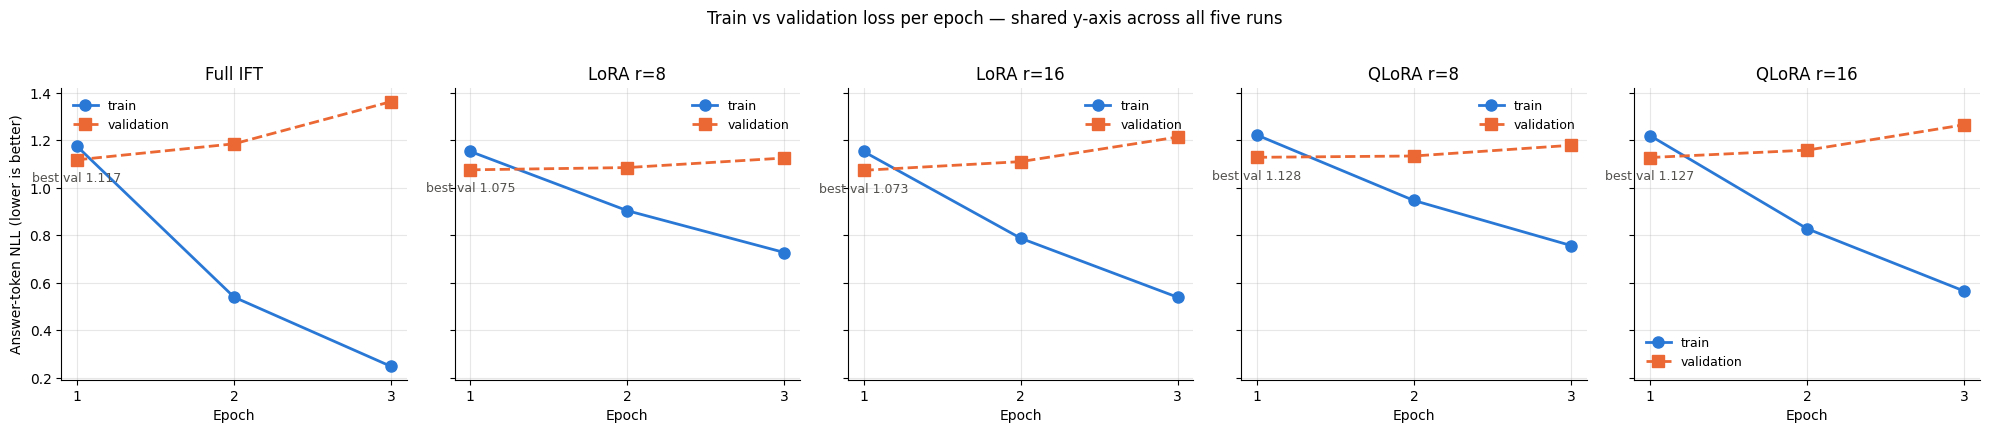

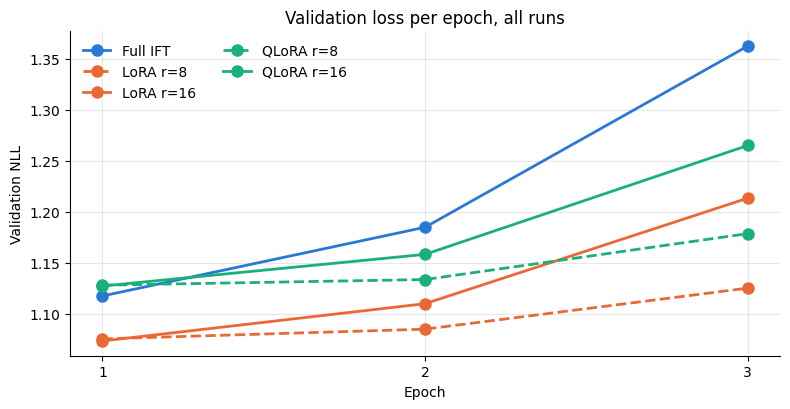

📌 [S10] loss summary per run
            train_e1  train_last  val_e1  val_last  val_best  best_epoch  val_minus_train_last
Full IFT      1.1744      0.2487  1.1174    1.3623    1.1174           1                1.1136
LoRA r=8      1.1527      0.7277  1.0754    1.1251    1.0754           1                0.3974
LoRA r=16     1.1525      0.5395  1.0733    1.2133    1.0733           1                0.6737
QLoRA r=8     1.2219      0.7572  1.1280    1.1785    1.1280           1                0.4213
QLoRA r=16    1.2193      0.5655  1.1272    1.2649    1.1272           1                0.6994


In [14]:
# ============================================================
#  Step 10: Plots — Train vs Validation Loss (per epoch)
# ============================================================

run_hists = ([("Full IFT", full_hist)]
             + [(f"LoRA r={r}", lora_runs[r]["hist"]) for r in LORA_RANKS]
             + [(f"QLoRA r={r}", qlora_runs[r]["hist"]) for r in LORA_RANKS])
C_TRAIN, C_VAL, INK = "#2a78d6", "#eb6834", "#52514e"

fig, axes = plt.subplots(1, len(run_hists), figsize=(4.0 * len(run_hists), 4.2), sharey=True)
for ax, (name, h) in zip(axes, run_hists):
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], "-o", color=C_TRAIN, lw=2, ms=8, label="train")
    ax.plot(ep, h["val_loss"], "--s", color=C_VAL, lw=2, ms=8, label="validation")
    b = int(np.argmin(h["val_loss"]))
    ax.annotate(f"best val {h['val_loss'][b]:.3f}", (ep[b], h["val_loss"][b]), textcoords="offset points",
                xytext=(0, -16), ha="center", fontsize=9, color=INK)
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_xticks(ep)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("Answer-token NLL (lower is better)")
fig.suptitle("Train vs validation loss per epoch — shared y-axis across all five runs", y=1.02)
plt.tight_layout()
plt.show()

# Validation curves overlaid: which run converges fastest / lowest?
style = {"Full IFT": ("#2a78d6", "-"), "LoRA r=8": ("#eb6834", "--"), "LoRA r=16": ("#eb6834", "-"),
         "QLoRA r=8": ("#1baf7a", "--"), "QLoRA r=16": ("#1baf7a", "-")}
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, h in run_hists:
    col, ls = style[name]
    ax.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], ls, marker="o", color=col, lw=2, ms=8, label=name)
ax.set_title("Validation loss per epoch, all runs")
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation NLL")
ax.set_xticks(np.arange(1, EPOCHS + 1))
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

loss_tbl = pd.DataFrame({name: {"train_e1": h["train_loss"][0], "train_last": h["train_loss"][-1],
                                "val_e1": h["val_loss"][0], "val_last": h["val_loss"][-1],
                                "val_best": min(h["val_loss"]), "best_epoch": int(np.argmin(h["val_loss"])) + 1,
                                "val_minus_train_last": h["val_loss"][-1] - h["train_loss"][-1]}
                         for name, h in run_hists}).T
loss_tbl["best_epoch"] = loss_tbl["best_epoch"].astype(int)
print("📌 [S10] loss summary per run")
print(loss_tbl.round(4).to_string())

### ✍️ Step 10 Reflection  <font color="red">**[2 marks]**</font>

**[Your Answer]** must cover:
- Which method converged fastest and to the lowest validation loss, and whether any run shows signs of **overfitting** (validation rising while training keeps falling). <font color="red">**[1 marks]**</font>
- Whether a lower *training* loss reliably predicted better *test* answers back in Step 9 — and what that tells you. <font color="red">**[1 marks]**</font>

*Cite the curves and the Step 9 numbers.*

### ✅ Your Answer — Step 10

**Convergence and overfitting.** All five runs reach their best validation loss **at epoch 1**, so they converge within a single pass over the 300 examples.

| Run | Best val loss (epoch 1) | Val loss, epoch 3 | Train loss, epoch 1 → 3 | Val − train gap, epoch 3 |
|---|---|---|---|---|
| LoRA r = 16 | **1.0733** | 1.2133 | 1.1525 → 0.5395 | 0.67 |
| LoRA r = 8 | 1.0754 | 1.1251 | 1.1527 → 0.7277 | 0.40 |
| Full IFT | 1.1174 | 1.3623 | 1.1744 → 0.2487 | 1.11 |
| QLoRA r = 16 | 1.1272 | 1.2649 | 1.2193 → 0.5655 | 0.70 |
| QLoRA r = 8 | 1.1280 | 1.1785 | 1.2219 → 0.7572 | 0.42 |

The lowest validation loss belongs to LoRA r = 16 (1.0733), essentially tied with LoRA r = 8 (1.0754).

**Every run then overfits:** validation rises while training keeps falling. The severity follows how much freedom each method has:
- **Full IFT** is by far the worst. Train drops from 1.1744 to 0.2487 while validation climbs from 1.1174 to 1.3623, leaving a 1.11 gap at epoch 3.
- **Rank 16** overfits faster than rank 8 for both LoRA and QLoRA.
- **The rank-8 adapters** are the mildest, with validation rising only about 0.05.

Early stopping restored the epoch-1 weights in every run.

**Did lower training loss predict better test answers? No; the relationship is inverted.**

| Run | Train loss, epoch 3 | Test ROUGE-L |
|---|---|---|
| Full IFT | 0.2487 (lowest) | 0.2946 (worst) |
| LoRA r = 16 | 0.5395 | 0.3201 |
| QLoRA r = 16 | 0.5655 | 0.3139 |
| LoRA r = 8 | 0.7277 | **0.3485 (best)** |
| QLoRA r = 8 | 0.7572 | 0.3167 |

Low training loss here measures memorisation of 300 answers, not generalisation. Validation loss is a better guide: the two LoRA runs have the lowest validation losses and the top two ROUGE-L scores. Even it is imperfect, though. Full IFT's best validation loss (1.1174) beats both QLoRA runs (1.127), yet it scores below them on ROUGE-L. Validation NLL scores each next token given the *reference* prefix (teacher forcing), whereas the test scores free-running greedy generation, including length and stopping behaviour. Model selection therefore has to rest on held-out data and on the generation metrics, not on the training curve.

## <font color="blue"><b>Step 11: Error Analysis</b></font>  <font color="red">**[8 marks]**</font>

Numbers alone don't tell you *how* a model is wrong. Take the best run by **ROUGE-L**, print a few of its generated answers next to the references, and back that up with a quantitative summary of the failure modes: predicted-vs-reference length, the length ratio (a quick proxy for rambling or truncation), and counts of empty / much-shorter / much-longer generations.

**Marks:** code <font color="red">**[4 marks]**</font> — select the best run by ROUGE-L, show sample generations vs references, and compute the length-ratio + failure-mode summary; reflection <font color="red">**[4 marks]**</font> — see below.

In [15]:
# ============================================================
#  Step 11: Error Analysis
# ============================================================
import textwrap

best_name = max(results, key=lambda k: results[k]["rougeL"])
best_preds = preds_store[best_name]
print(f"Best run by ROUGE-L: {best_name} -> {results[best_name]}\n")

per_ex_rl = np.array(rouge.compute(predictions=best_preds, references=test_refs, rouge_types=["rougeL"],
                                   use_stemmer=True, use_aggregator=False)["rougeL"], dtype=float)
order = np.argsort(per_ex_rl)
samples = [("highest ROUGE-L", order[-1]), ("upper-middle", order[(3 * len(order)) // 4]),
           ("median", order[len(order) // 2]), ("lowest ROUGE-L", order[0])]

def _wrap(s, limit=900):
    s = s if len(s) <= limit else s[:limit] + " [...]"
    return "\n".join(textwrap.fill(line, 110) for line in s.splitlines() if line.strip())

for label, i in samples:
    r = test_df.iloc[i]
    print("=" * 112)
    print(f"[{label}] test #{i} | ROUGE-L {per_ex_rl[i]:.3f} | words: model {len(best_preds[i].split())} "
          f"vs reference {len(test_refs[i].split())}")
    print("-" * 112)
    print("INSTRUCTION:", _wrap(r["instruction"], 400))
    if r["input"]:
        print("INPUT:", _wrap(r["input"], 400))
    print("\nREFERENCE (text-davinci-003):\n" + _wrap(test_refs[i]))
    print(f"\nMODEL ANSWER ({best_name}):\n" + (_wrap(best_preds[i]) or "<EMPTY>"))
print("=" * 112)

Best run by ROUGE-L: lora_r8 -> {'rougeL': 0.3485, 'bertscore_f1': 0.9011, 'pct_trainable': 0.88, 'peak_mem_gb': 3.99, 'train_time_s': 274.6}

[highest ROUGE-L] test #9 | ROUGE-L 1.000 | words: model 6 vs reference 6
----------------------------------------------------------------------------------------------------------------
INSTRUCTION: Identify if the provided condition is a physiological or psychological disorder.
INPUT: "Anorexia nervosa

REFERENCE (text-davinci-003):
Anorexia nervosa is a psychological disorder.

MODEL ANSWER (lora_r8):
Anorexia nervosa is a psychological disorder.
[upper-middle] test #17 | ROUGE-L 0.372 | words: model 17 vs reference 26
----------------------------------------------------------------------------------------------------------------
INSTRUCTION: Identify which part of brain controls the sense of smell.
INPUT: Which area of the brain is responsible for processing sensory information related to smell? A) Frontal Lobe B)
Parietal Lobe C) Temporal L

Failure-mode summary for lora_r8 on 30 test prompts
  examples                             30
  mean pred words                      108.67
  mean ref words                       139.97
  median length ratio (pred/ref)       0.71
  mean length ratio                    1.11
  empty generations                    0
  much shorter (<0.5x ref)             2
  much longer (>2x ref)                2
  hit 200-token cap (cut off)          14
  answers with a safety caveat         0
  references with a safety caveat      4
  corr(len_ratio, ROUGE-L)             0.02


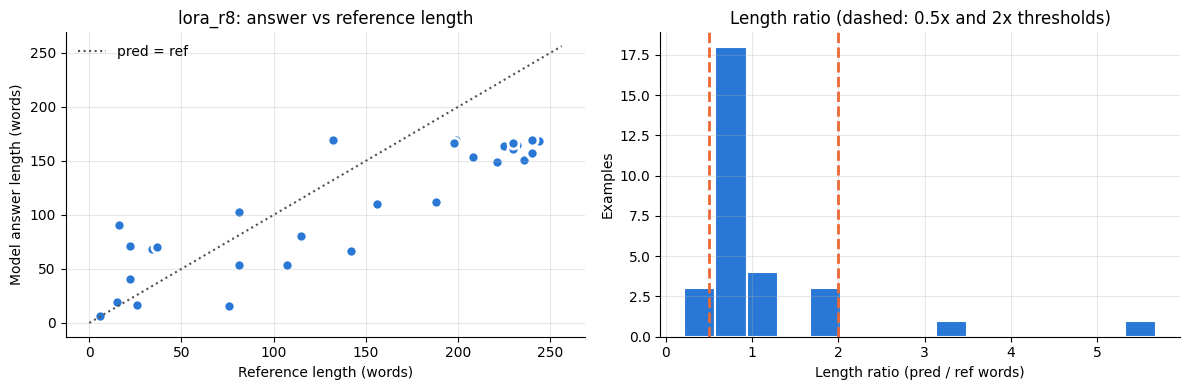


📌 [S11] length / failure profile, all runs (mean reference length 140 words)
           rougeL  mean_pred_words  median_len_ratio  empty  much_shorter  much_longer  hit_cap  caveats
full_ift    0.295          116.900             0.736    0.0           2.0          6.0     14.0      4.0
lora_r8     0.348          108.667             0.712    0.0           2.0          2.0     14.0      0.0
lora_r16    0.320          103.933             0.700    0.0           2.0          4.0     11.0      2.0
qlora_r8    0.317          112.333             0.704    0.0           1.0          6.0     12.0      4.0
qlora_r16   0.314          112.133             0.769    0.0           3.0          6.0     15.0      7.0


In [16]:
# ---- Quantitative summary of the errors ----
import re
CAVEAT_RE = (r"consult|healthcare (?:provider|professional)|medical (?:advice|attention|professional)|"
             r"see a (?:doctor|physician)|seek (?:immediate |urgent )?(?:medical )?(?:help|care|attention)")
GEN_CAP = 200   # max_new_tokens used in generate_answers

def error_profile(preds, refs):
    pw = np.array([len(p.split()) for p in preds])
    rw = np.array([len(r.split()) for r in refs])
    ptok = np.array([len(tokenizer(p, add_special_tokens=False)["input_ids"]) for p in preds])
    ratio = pw / np.maximum(rw, 1)
    return pd.DataFrame({"pred_words": pw, "ref_words": rw, "len_ratio": ratio,
                         "hit_token_cap": ptok >= GEN_CAP - 2,
                         "pred_caveat": [bool(re.search(CAVEAT_RE, p, re.I)) for p in preds],
                         "ref_caveat":  [bool(re.search(CAVEAT_RE, r, re.I)) for r in refs]})

prof = error_profile(best_preds, test_refs)
prof["rougeL"] = per_ex_rl
n = len(prof)
summary = {
    "examples": n,
    "mean pred words": prof["pred_words"].mean(), "mean ref words": prof["ref_words"].mean(),
    "median length ratio (pred/ref)": prof["len_ratio"].median(), "mean length ratio": prof["len_ratio"].mean(),
    "empty generations": int((prof["pred_words"] == 0).sum()),
    "much shorter (<0.5x ref)": int((prof["len_ratio"] < 0.5).sum()),
    "much longer (>2x ref)": int((prof["len_ratio"] > 2.0).sum()),
    f"hit {GEN_CAP}-token cap (cut off)": int(prof["hit_token_cap"].sum()),
    "answers with a safety caveat": int(prof["pred_caveat"].sum()),
    "references with a safety caveat": int(prof["ref_caveat"].sum()),
    "corr(len_ratio, ROUGE-L)": prof["len_ratio"].corr(prof["rougeL"]),
}
print(f"Failure-mode summary for {best_name} on {n} test prompts")
for k, v in summary.items():
    print(f"  {k:<36} {v:.2f}" if isinstance(v, float) else f"  {k:<36} {v}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(prof["ref_words"], prof["pred_words"], s=64, color="#2a78d6", edgecolor="white", linewidth=2)
lim = max(prof["ref_words"].max(), prof["pred_words"].max()) * 1.05
axes[0].plot([0, lim], [0, lim], ":", color="#52514e", lw=1.5, label="pred = ref")
axes[0].set(xlabel="Reference length (words)", ylabel="Model answer length (words)",
            title=f"{best_name}: answer vs reference length")
axes[0].legend(frameon=False)
axes[1].hist(prof["len_ratio"], bins=15, color="#2a78d6", edgecolor="white", linewidth=1.5)
for x in (0.5, 2.0):
    axes[1].axvline(x, color="#eb6834", ls="--", lw=2)
axes[1].set(xlabel="Length ratio (pred / ref words)", ylabel="Examples",
            title="Length ratio (dashed: 0.5x and 2x thresholds)")
for ax in axes:
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

# Same profile for every run, so the best run's behaviour can be put in context.
rows = {}
for name, p in preds_store.items():
    pr = error_profile(p, test_refs)
    rows[name] = {"rougeL": results[name]["rougeL"], "mean_pred_words": pr["pred_words"].mean(),
                  "median_len_ratio": pr["len_ratio"].median(), "empty": int((pr["pred_words"] == 0).sum()),
                  "much_shorter": int((pr["len_ratio"] < 0.5).sum()), "much_longer": int((pr["len_ratio"] > 2).sum()),
                  "hit_cap": int(pr["hit_token_cap"].sum()), "caveats": int(pr["pred_caveat"].sum())}
print("\n📌 [S11] length / failure profile, all runs (mean reference length "
      f"{prof['ref_words'].mean():.0f} words)")
print(pd.DataFrame(rows).T.round(3).to_string())

### ✍️ Step 11 Reflection  <font color="red">**[4 marks]**</font>

**[Your Answer]** must cover:
- One recurring way the model's answers differ from the references — length, specificity, hedging, or missing safety caveats — with a concrete example from the samples. <font color="red">**[2 marks]**</font>
- What the length-ratio and failure counts reveal about the model's behaviour (rambling, truncation, empty generations). <font color="red">**[1 marks]**</font>
- One concrete change you would try to reduce these errors (e.g. more epochs, higher rank, longer `MAX_LEN`, or different decoding settings). <font color="red">**[1 marks]**</font>

*Cite the samples and the summary numbers your run produced.*

### ✅ Your Answer — Step 11

**A recurring difference from the references: answers are shorter, often cut off, and less specific, and safety caveats are dropped.** The best run by ROUGE-L is **LoRA r = 8** (ROUGE-L 0.3485). Its answers average **108.7 words against 140.0** for the references, with a median length ratio of **0.71**.

The clearest example is **test #3**, *"Develop a brief report on recent measles outbreak…"*. The model copies davinci's report structure almost word for word (*"Title: Recent Measles Outbreak: Causes, Spread, Control Measures, and Public Health Implications / Introduction: …"*), which earns it ROUGE-L 0.310. But it stops at **164 words against 225**, and it states something false with confidence: that the outbreak is caused by *"a reassortment of the measles virus … when two different measles viruses combine"*. Measles has a non-segmented genome and does not reassort; the reference correctly attributes outbreaks to transmission among non-immune people.

**Test #1**, communicating a cancer relapse, has the lowest ROUGE-L at **0.165**. The model gives a generic numbered checklist (*"1. Listen actively … 2. Provide information … 4. Offer resources"*) where the reference writes an actual empathetic script to the patient. The model also omits the safety caveats the references carry: **0 of 30** LoRA r = 8 answers contain one, against **4 of 30** references.

**What the length statistics reveal.**

| | Value |
|---|---|
| Empty generations | **0 / 30** |
| Much shorter (< 0.5×) | **2 / 30** |
| Much longer (> 2×) | **2 / 30** |
| Hit the 200-token cap | **14 / 30** |
| Median length ratio | 0.71 |
| Mean length ratio | 1.11 |
| corr(length ratio, ROUGE-L) | **0.02** |

- **The dominant failure is truncation, not rambling or empties.** Almost half the answers run into the `max_new_tokens = 200` cap. That cap is below the reference length for many prompts: output p95 is 303 tokens, and the mean reference length is 140 words, roughly 190 tokens.
- **There are no empty generations.** The model always starts answering and stops cleanly when it finishes early, because EOS was supervised.
- **A few short references inflate the mean ratio.** The mean (1.11) sits above the median (0.71) because of short references such as #9, where 6 words is a perfect match.
- **Length does not explain the ROUGE-L gap.** With a correlation of 0.02, the shortfall comes from wording and content differences at similar length.
- **The pattern is shared.** The other runs show the same profile (11–15 cap hits each).

**One concrete change: raise the length budgets.** I would set `max_new_tokens = 320`, which covers the output p95 of 303 tokens, and `MAX_LEN = 400`, which covers the templated p95 of 393. Today 56.7% of training answers are clipped mid-answer and 14 of 30 test answers are cut off.

The adapter runs peak at only about 3–4 GB, so the T4 easily has room for this. Combined with training for **one epoch** (every run peaked at epoch 1), the extra compute stays roughly unchanged.

## <font color="blue"><b>Step 12: Parameter Analysis</b></font>  <font color="red">**[6 marks]**</font>

Bring everything together into the cost–quality picture. Build one comparison table across all five runs — **quality** (ROUGE-L, BERTScore-F1) against **cost** (% trainable parameters, peak GPU memory, training time) — then draw the supporting charts: quality bars with peak memory annotated, and a trainable-% bar chart that makes the full-IFT-vs-adapter gap obvious.

**Marks:** code <font color="red">**[4 marks]**</font> — the comparison table over all runs and the quality + trainable-% charts; reflection <font color="red">**[2 marks]**</font> — see below.

In [17]:
# ============================================================
#  Step 12: Parameter Analysis
# ============================================================

# ---- Comparison table: quality vs cost across every run ----
RUN_ORDER = ["full_ift"] + [f"lora_r{r}" for r in LORA_RANKS] + [f"qlora_r{r}" for r in LORA_RANKS]
LABELS = {"full_ift": "Full IFT", **{f"lora_r{r}": f"LoRA r={r}" for r in LORA_RANKS},
          **{f"qlora_r{r}": f"QLoRA r={r}" for r in LORA_RANKS}}
abs_trainable = {"full_ift": tr_full,
                 **{f"lora_r{r}": lora_runs[r]["trainable"] for r in LORA_RANKS},
                 **{f"qlora_r{r}": qlora_runs[r]["trainable"] for r in LORA_RANKS}}
best_val = {"full_ift": min(full_hist["val_loss"]),
            **{f"lora_r{r}": min(lora_runs[r]["hist"]["val_loss"]) for r in LORA_RANKS},
            **{f"qlora_r{r}": min(qlora_runs[r]["hist"]["val_loss"]) for r in LORA_RANKS}}

cmp_df = pd.DataFrame(results).T.loc[RUN_ORDER, ["rougeL", "bertscore_f1", "pct_trainable", "peak_mem_gb", "train_time_s"]]
cmp_df = cmp_df.astype(float)
cmp_df.insert(2, "trainable_params", pd.Series(abs_trainable).astype(int))
cmp_df.insert(2, "best_val_loss", pd.Series(best_val).round(4))
ref = cmp_df.loc["full_ift"]
cmp_df["rougeL_vs_full"] = (cmp_df["rougeL"] - ref["rougeL"]).round(4)
cmp_df["mem_vs_full"] = (cmp_df["peak_mem_gb"] / ref["peak_mem_gb"]).round(2)
cmp_df["time_vs_full"] = (cmp_df["train_time_s"] / ref["train_time_s"]).round(2)
cmp_df = cmp_df.sort_values("rougeL", ascending=False)
cmp_df.index = [LABELS[i] for i in cmp_df.index]
print("Quality vs cost (sorted by ROUGE-L; peak memory is the isolated per-run CUDA peak)")
display(cmp_df.style.format({"rougeL": "{:.4f}", "bertscore_f1": "{:.4f}", "best_val_loss": "{:.4f}",
                             "trainable_params": "{:,}", "pct_trainable": "{:.2f}%", "peak_mem_gb": "{:.2f}",
                             "train_time_s": "{:.1f}", "rougeL_vs_full": "{:+.4f}", "mem_vs_full": "{:.2f}x",
                             "time_vs_full": "{:.2f}x"}))

for r in LORA_RANKS:
    l, q = results[f"lora_r{r}"], results[f"qlora_r{r}"]
    print(f"📌 [S12 r={r}] QLoRA vs LoRA: mem {q['peak_mem_gb'] - l['peak_mem_gb']:+.2f} GB "
          f"({q['peak_mem_gb'] / l['peak_mem_gb'] - 1 if l['peak_mem_gb'] > 0 else float('nan'):+.0%}) | "
          f"time {q['train_time_s'] - l['train_time_s']:+.1f}s | "
          f"ROUGE-L {q['rougeL'] - l['rougeL']:+.4f} | BERTScore {q['bertscore_f1'] - l['bertscore_f1']:+.4f}")
for m in ["lora", "qlora"]:
    a, b = results[f"{m}_r8"], results[f"{m}_r16"]
    print(f"📌 [S12 {m}] r16 vs r8: ROUGE-L {b['rougeL'] - a['rougeL']:+.4f} | BERTScore {b['bertscore_f1'] - a['bertscore_f1']:+.4f} | "
          f"mem {b['peak_mem_gb'] - a['peak_mem_gb']:+.2f} GB | time {b['train_time_s'] - a['train_time_s']:+.1f}s")

Quality vs cost (sorted by ROUGE-L; peak memory is the isolated per-run CUDA peak)


,rougeL,bertscore_f1,best_val_loss,trainable_params,pct_trainable,peak_mem_gb,train_time_s,rougeL_vs_full,mem_vs_full,time_vs_full
LoRA r=8,0.3485,0.9011,1.0754,"4,399,104",0.88%,3.99,274.6,+0.0539,0.40x,0.82x
LoRA r=16,0.3201,0.8980,1.0733,"8,798,208",1.75%,4.05,274.8,+0.0255,0.41x,0.82x
QLoRA r=8,0.3167,0.8915,1.1280,"4,399,104",0.88%,2.75,168.9,+0.0221,0.28x,0.50x
QLoRA r=16,0.3139,0.8856,1.1272,"8,798,208",1.75%,2.80,170.9,+0.0193,0.28x,0.51x
Full IFT,0.2946,0.8925,1.1174,"494,032,768",100.00%,9.93,335.4,+0.0000,1.00x,1.00x


📌 [S12 r=8] QLoRA vs LoRA: mem -1.24 GB (-31%) | time -105.7s | ROUGE-L -0.0318 | BERTScore -0.0096
📌 [S12 r=16] QLoRA vs LoRA: mem -1.25 GB (-31%) | time -103.9s | ROUGE-L -0.0062 | BERTScore -0.0124
📌 [S12 lora] r16 vs r8: ROUGE-L -0.0284 | BERTScore -0.0031 | mem +0.06 GB | time +0.2s
📌 [S12 qlora] r16 vs r8: ROUGE-L -0.0028 | BERTScore -0.0059 | mem +0.05 GB | time +2.0s


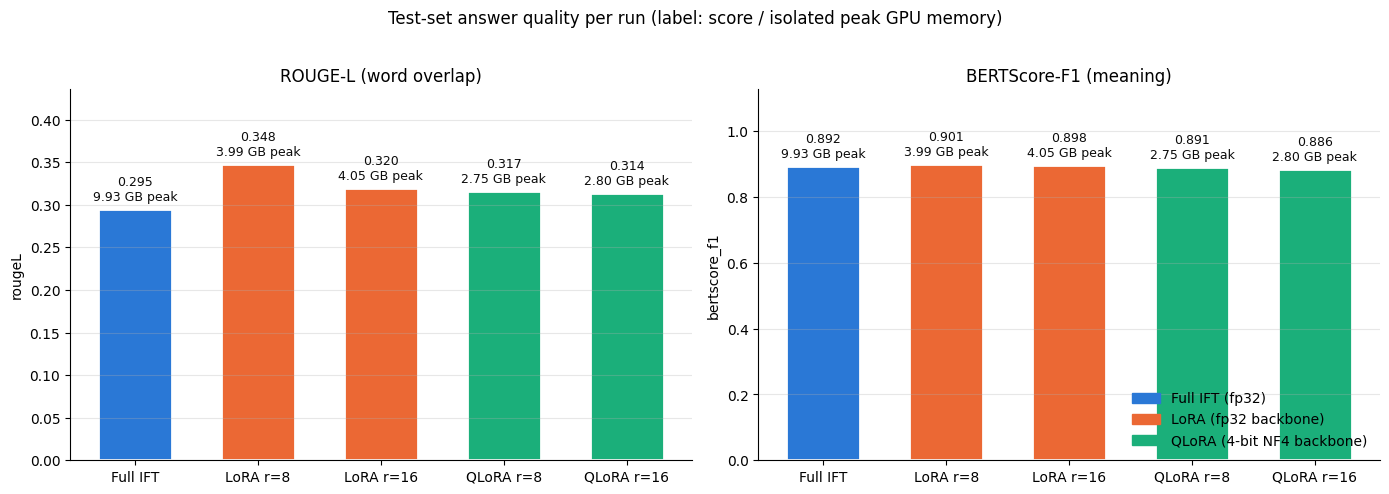

In [18]:
# ---- Quality chart with peak memory annotated ----
METHOD_COLOR = {"full_ift": "#2a78d6", "lora_r8": "#eb6834", "lora_r16": "#eb6834",
                "qlora_r8": "#1baf7a", "qlora_r16": "#1baf7a"}
x = np.arange(len(RUN_ORDER))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric, title in zip(axes, ["rougeL", "bertscore_f1"], ["ROUGE-L (word overlap)", "BERTScore-F1 (meaning)"]):
    vals = [results[n][metric] for n in RUN_ORDER]
    bars = ax.bar(x, vals, width=0.6, color=[METHOD_COLOR[n] for n in RUN_ORDER], edgecolor="white", linewidth=2)
    for b, n in zip(bars, RUN_ORDER):
        ax.annotate(f"{results[n][metric]:.3f}\n{results[n]['peak_mem_gb']:.2f} GB peak",
                    (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, color="#0b0b0b")
    ax.set_xticks(x, [LABELS[n] for n in RUN_ORDER])
    ax.set_ylim(0, max(max(vals), 1e-3) * 1.25)
    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#2a78d6", "#eb6834", "#1baf7a"]]
axes[1].legend(handles, ["Full IFT (fp32)", "LoRA (fp32 backbone)", "QLoRA (4-bit NF4 backbone)"],
               frameon=False, loc="lower right")
fig.suptitle("Test-set answer quality per run (label: score / isolated peak GPU memory)", y=1.02)
plt.tight_layout(); plt.show()

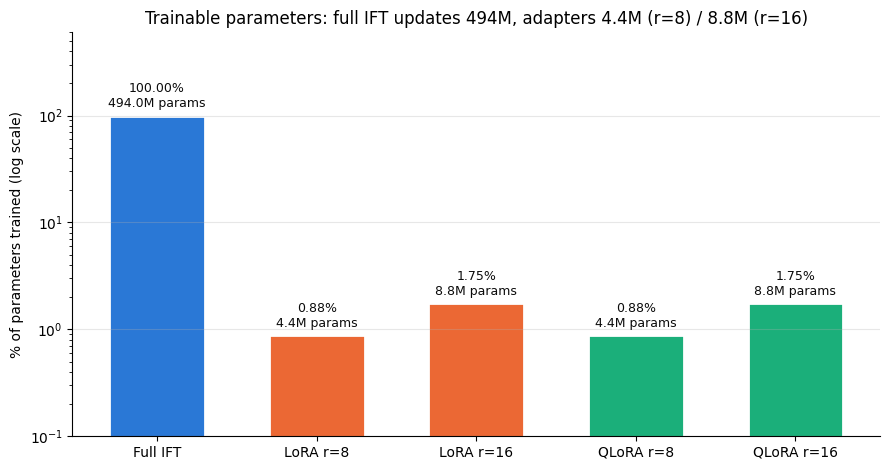

In [19]:
# ---- Trainable-parameters comparison (the LoRA/QLoRA story) ----
fig, ax = plt.subplots(figsize=(9, 4.8))
pcts = [results[n]["pct_trainable"] for n in RUN_ORDER]
bars = ax.bar(x, pcts, width=0.6, color=[METHOD_COLOR[n] for n in RUN_ORDER], edgecolor="white", linewidth=2)
for b, n in zip(bars, RUN_ORDER):
    ax.annotate(f"{results[n]['pct_trainable']:.2f}%\n{abs_trainable[n] / 1e6:.1f}M params",
                (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=9, color="#0b0b0b")
ax.set_yscale("log")
ax.set_ylim(0.1, 600)
ax.set_xticks(x, [LABELS[n] for n in RUN_ORDER])
ax.set_ylabel("% of parameters trained (log scale)")
ax.set_title(f"Trainable parameters: full IFT updates {tr_full / 1e6:.0f}M, adapters "
             f"{abs_trainable['lora_r8'] / 1e6:.1f}M (r=8) / {abs_trainable['lora_r16'] / 1e6:.1f}M (r=16)")
ax.grid(axis="y", alpha=0.3, which="major"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### ✍️ Step 12 Reflection  <font color="red">**[2 marks]**</font>

**[Your Answer]** must cover:
- Which method gives the best **balance** of quality, trainable-%, memory, and training time for a free T4 — not simply the highest score — citing the comparison table. <font color="red">**[1 mark]**</font>
- How **rank** (8 vs 16) and **quantisation** (LoRA vs QLoRA) each traded answer quality against cost. <font color="red">**[1 mark]**</font>

*Cite the actual numbers from your comparison table.*

### ✅ Your Answer — Step 12

**Best balance on a free T4: LoRA r = 8.**

| Run | ROUGE-L | BERTScore-F1 | Trainable | Peak memory | Time |
|---|---|---|---|---|---|
| **LoRA r = 8** | **0.3485** | **0.9011** | 4.4M (0.88%) | 3.99 GB | 274.6 s |
| LoRA r = 16 | 0.3201 | 0.8980 | 8.8M (1.75%) | 4.05 GB | 274.8 s |
| QLoRA r = 8 | 0.3167 | 0.8915 | 4.4M (0.88%) | 2.75 GB | **168.9 s** |
| QLoRA r = 16 | 0.3139 | 0.8856 | 8.8M (1.75%) | 2.80 GB | 170.9 s |
| Full IFT | 0.2946 | 0.8925 | 494M (100%) | 9.93 GB | 335.4 s |

LoRA r = 8 is the best balance, not merely the top score. It has the **highest quality on both metrics** (ROUGE-L 0.3485, which is +0.0539 over full IFT). It does this while training **0.88% of the parameters (4.4M vs 494M, 112× fewer)**, peaking at **3.99 GB (0.40× full IFT's 9.93 GB)** and training in **274.6 s (0.82× full IFT's 335.4 s)**. Its adapter checkpoint is a few MB instead of 2 GB.

Full IFT is dominated on every axis here: the most memory, the longest time and the lowest ROUGE-L, because it memorised the 300 examples.

QLoRA r = 8 is the runner-up and the right pick when memory or time binds. It is the cheapest run (2.75 GB, 0.28× full IFT's memory, and the fastest at 168.9 s) and still beats full IFT on ROUGE-L (0.3167). For a 0.5B model on a 15 GB T4, however, 4 GB is not a binding constraint, so LoRA r = 8's extra quality is worth its 1.24 GB.

**How rank traded quality against cost (8 → 16).** Rank 16 doubles the trainable parameters (4.4M → 8.8M, 0.88% → 1.75%) at almost no memory or time cost (+0.06 GB / +0.2 s for LoRA, +0.05 GB / +2.0 s for QLoRA). It bought **no quality**:

| | ROUGE-L | BERTScore-F1 |
|---|---|---|
| LoRA, r16 − r8 | −0.0284 | −0.0031 |
| QLoRA, r16 − r8 | −0.0028 | −0.0059 |

Best validation loss was unchanged (Δ −0.0020 for LoRA, −0.0008 for QLoRA), and the extra capacity went into faster overfitting.

**How quantisation traded quality against cost (LoRA → QLoRA).** At the same rank, the 4-bit backbone **cut peak memory by 31% (−1.24 / −1.25 GB)** and, on the T4's fp16 tensor cores, **training time by 38% (−105.7 s / −103.9 s)**. The price was a small, consistent quality loss:

| | ROUGE-L | BERTScore-F1 | Best val loss |
|---|---|---|---|
| r = 8 | −0.0318 | −0.0096 | +0.05 |
| r = 16 | −0.0062 | −0.0124 | +0.05 |

The trainable count is unchanged. On this task, **rank is not worth paying for, while quantisation is a fair memory-and-time-for-quality trade** whose value grows with model size.

In [20]:
# END OF THE NOTEBOOK --------------------------------